# Irony detection in tweets — Mini-projet Machine Learning

**Group:** Manar Mrabet (EDA & cleaning) · Sabrine Zouaoui (vectorization, Naive Bayes, Logistic Regression) · Roeya Stiti (SVM, Random Forest, KNN) · Mohamed Chaker Iben Hadj Amor (transformer fine-tuning)
**Dataset:** TweetEval `irony` (SemEval-2018 Task 3) — 2,862 training / 955 validation / 784 test tweets, labels 0 = non-ironic, 1 = ironic
**Course:** Machine Learning — FSB, Cycle Ingénieur
**Tools:** Python 3.12 · pandas · scikit-learn · matplotlib · PyTorch · Hugging Face Transformers

This notebook gathers the five notebooks of the project, in order, with their outputs:

1. Exploratory data analysis & text cleaning
2. Vectorization, Naive Bayes & Logistic Regression
3. SVM, Random Forest & KNN
4. Transformer fine-tuning (Twitter-RoBERTa)
5. Final comparison, choice of the model & conclusion

The individual notebooks and the shared code (`src/`) are in the project repository.

---

# Part 1 — Exploratory data analysis & text cleaning

*(source: `notebooks/01_eda_cleaning.ipynb`)*

## Irony Detection in Tweets — Machine Learning Mini-Project

**Dataset:** TweetEval – Irony (binary classification: `1` = irony, `0` = non_irony)


### Part A: Exploratory Data Analysis (EDA) and Text Preprocessing

In this notebook we:
1. explore the data (columns, classes, text length, plots);
2. clean the tweets and create the `text_clean` column used by the models.

### 0. Setup

In [1]:
import sys
sys.path.append("..")   # lets us import the shared code from the src/ folder

import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

from src.config import RANDOM_STATE, LABEL_NAMES, PROCESSED_DIR   # shared settings
from src.data import load_split, drop_corrupted_rows              # data loading
from src.cleaning import clean_text, STOPS_ALL, STOPS_KEEP_NEG    # text cleaning

sns.set_theme(style="whitegrid")   # plot style: white background with a grid

## 1. Exploratory Data Analysis (EDA)

### 1.1 Loading the data
Text and labels are stored in separate files (one tweet per line), so `load_split` reads both and builds a DataFrame with the columns `text` and `label`.

In [2]:
# Load the three official splits
train = load_split("train")
val = load_split("val")
test = load_split("test")

# Show (number of rows, number of columns) of each split
print("train :", train.shape)
print("val   :", val.shape)
print("test  :", test.shape)

train : (2862, 2)
val   : (955, 2)
test  : (784, 2)


The train split contains 3 corrupted rows: several tweets were merged on the same line, separated by tab characters.
We remove them from the train split only (validation and test are not modified).

In [3]:
# Count the corrupted rows (they contain a tab character)
print("Corrupted rows in train:", train["text"].str.contains("\t").sum())

# Remove them and check the new size (2862 - 3 = 2859)
train = drop_corrupted_rows(train)
print("train :", train.shape)
assert len(train) == 2859

Corrupted rows in train: 3
train : (2859, 2)


### 1.2 Available columns

In [4]:
# First 10 rows
train.head(10)

,text,label
0,seeing ppl walking w/ crutches makes me really...,1
1,"look for the girl with the broken smile, ask h...",0
2,Now I remember why I buy books online @user #s...,1
3,@user @user So is he banded from wearing the c...,1
4,Just found out there are Etch A Sketch apps. ...,1
5,"Hey what do you know, one of the witnesses sup...",1
6,@user on stage at #flzjingleball at the @user ...,0
7,You know it's going to be a great day when you...,1
8,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me hi...,1


In [5]:
# Column names, types and number of non-empty values
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2859 entries, 0 to 2858
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    2859 non-null   str  
 1   label   2859 non-null   int64
dtypes: int64(1), str(1)
memory usage: 44.8 KB


In [6]:
# Basic statistics of the numeric columns (only label for now)
train.describe()

,label
count,2859.000000
mean,0.505421
std,0.500058
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


The DataFrame has two columns: `text` (the tweet) and `label` (0 = non_irony, 1 = irony), with no missing values.
The mean of `label` is close to 0.5, so the two classes are almost balanced in the train split.

### 1.3 Class distribution

In [7]:
# Number and percentage of tweets per class, for each split
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name)
    print(df["label"].value_counts().sort_index())
    print(df["label"].value_counts(normalize=True).sort_index().round(3) * 100)
    print()

train
label
0    1414
1    1445
Name: count, dtype: int64
label
0    49.5
1    50.5
Name: proportion, dtype: float64

val
label
0    499
1    456
Name: count, dtype: int64
label
0    52.3
1    47.7
Name: proportion, dtype: float64

test
label
0    473
1    311
Name: count, dtype: int64
label
0    60.3
1    39.7
Name: proportion, dtype: float64



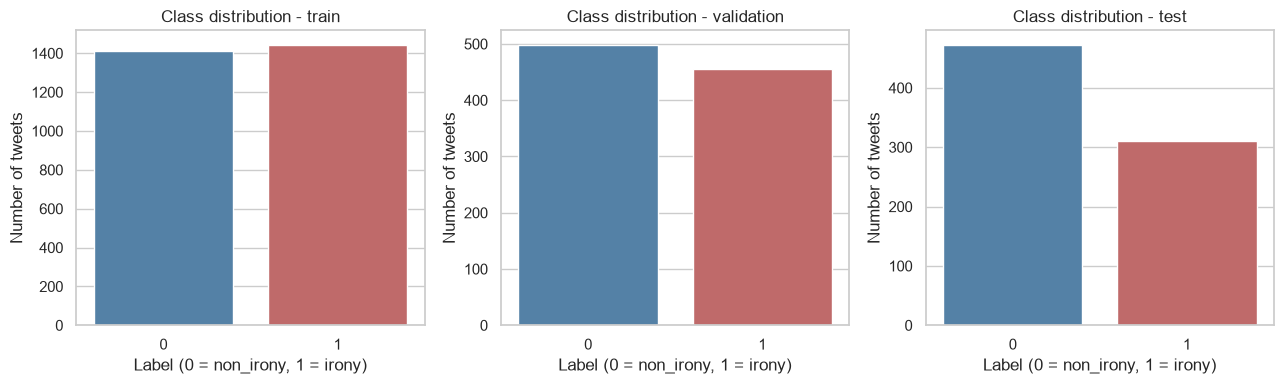

In [8]:
# Bar plot of the class distribution (one plot per split)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, name, df in zip(axes, ["train", "validation", "test"], [train, val, test]):
    sns.countplot(x="label", hue="label", data=df, ax=ax, palette=["steelblue", "indianred"], legend=False)
    ax.set_title("Class distribution - " + name)
    ax.set_xlabel("Label (0 = non_irony, 1 = irony)")
    ax.set_ylabel("Number of tweets")

plt.tight_layout()
plt.show()

The train split (1414 non_irony / 1445 irony) and the validation split (499 / 456) are almost balanced.
The test split is not: 473 non-ironic tweets against 311 ironic ones (about 60% / 40%).
For this reason we will not rely on accuracy alone: we will mainly use the macro F1-score, which gives the same weight to both classes.

### 1.4 Text length

In [9]:
# Add two columns: number of characters and number of words of each tweet
train["n_chars"] = train["text"].str.len()
train["n_words"] = train["text"].str.split().str.len()

train[["n_chars", "n_words"]].describe()

,n_chars,n_words
count,2859.000000,2859.000000
mean,78.780693,13.521861
std,32.416796,5.871894
min,6.000000,1.000000
25%,52.000000,9.000000
50%,78.000000,13.000000
75%,106.000000,18.000000
max,141.000000,33.000000


In [10]:
# Average length of each class
train.groupby("label")[["n_chars", "n_words"]].mean().round(1)

,n_chars,n_words
label,,
0,79.3,13.5
1,78.2,13.5


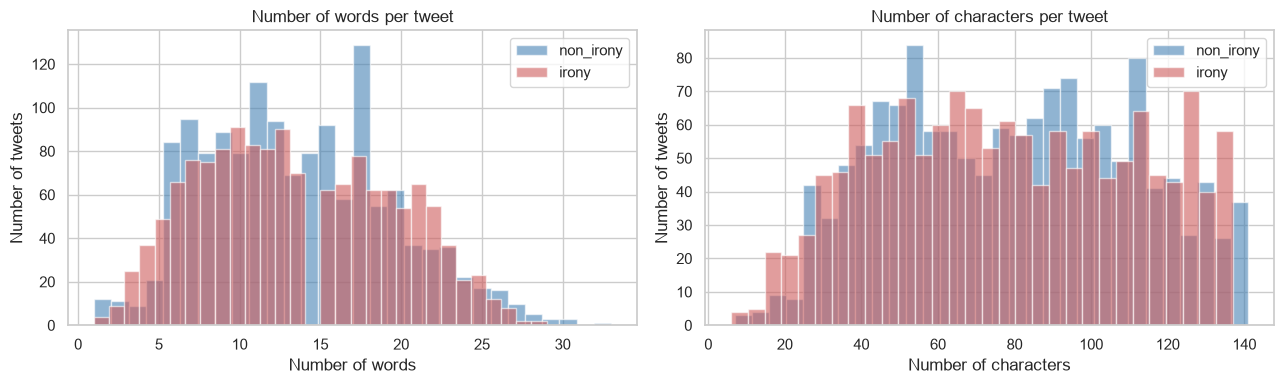

In [11]:
# Histograms of the length (words and characters), one color per class
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for col, ax, unit in zip(["n_words", "n_chars"], axes, ["words", "characters"]):
    ax.hist(train[train["label"] == 0][col], bins=30, alpha=0.6, label=LABEL_NAMES[0], color="steelblue")
    ax.hist(train[train["label"] == 1][col], bins=30, alpha=0.6, label=LABEL_NAMES[1], color="indianred")
    ax.set_title("Number of " + unit + " per tweet")
    ax.set_xlabel("Number of " + unit)
    ax.set_ylabel("Number of tweets")
    ax.legend()

plt.tight_layout()
plt.show()

A tweet has 13 to 14 words on average (about 79 characters), with a maximum of 33 words and 141 characters once the corrupted rows are removed.
Both classes have almost the same length (13.5 words on average in each class), so the length alone does not help to detect irony.

### 1.5 WordClouds: most frequent words per class

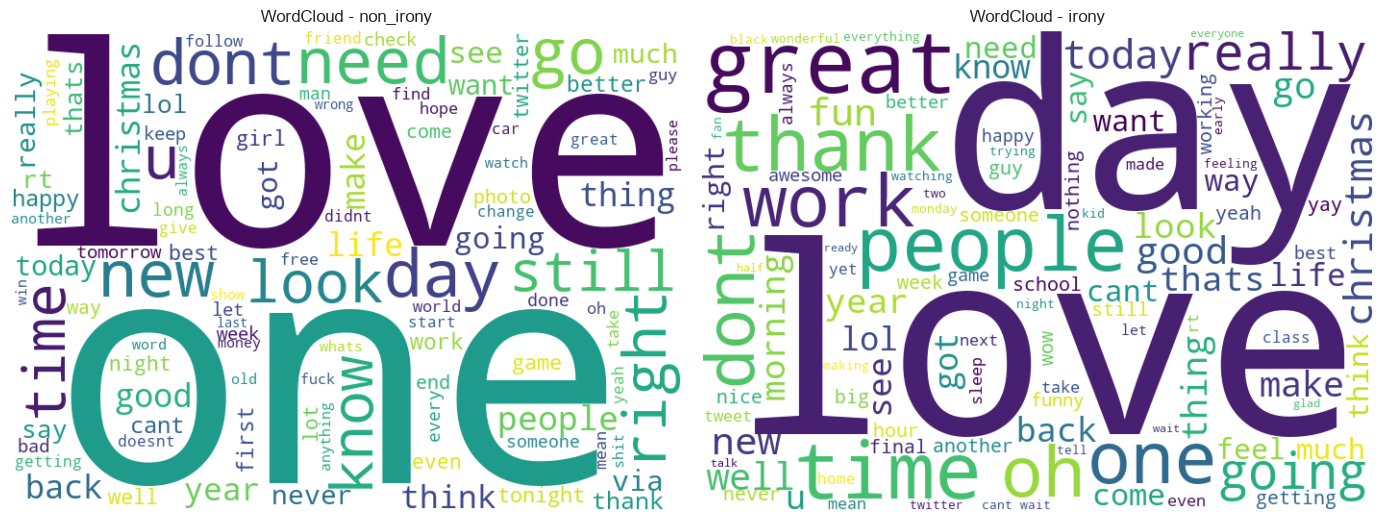

In [12]:
# Words ignored in the clouds: English stopwords + a few useless tokens
ignored_words = set(STOPWORDS) | {"user", "http", "https", "co", "amp"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, lab in zip(axes, [0, 1]):
    # Remove links and mentions (default clean_text), then join all tweets of the class into one text
    texts = train[train["label"] == lab]["text"].apply(clean_text)
    cloud = WordCloud(width=700, height=500, background_color="white", stopwords=ignored_words,
                      max_words=100, random_state=RANDOM_STATE).generate(" ".join(texts))
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title("WordCloud - " + LABEL_NAMES[lab])
    ax.axis("off")

plt.tight_layout()
plt.show()

The two clouds are different. In the irony class we mostly see positive words (*love*, *great*, *fun*, *thank*, *nice*, *awesome*, *wow*, *yay*).
In the non_irony class the dominant words are more neutral (*will*, *one*, *new*, *think*, *need*).
Positive words are therefore more frequent in ironic tweets, which explains why irony is hard to detect: the same words are also used sincerely.

## 2. Text Preprocessing

### 2.1 What the tweets contain

In [13]:
# 8 random tweets (fixed seed so we always see the same ones)
pd.set_option("display.max_colwidth", 200)
train[["text", "label"]].sample(8, random_state=RANDOM_STATE)

,text,label
1584,@user doesn't lucky and fortunate mean the same thing?,1
1746,Drinking an Imperial IPA (2014-) by @user - #photo,0
772,I love being on hold. Especially when the music is so great.,1
1729,Look! It's a white Christmas after all! #MinnesotaProblems,1
387,#almajmoua participating in the 4th #CSR forum #lebanon #togetherwegrow -for-profit #microfinance #supporting...,0
407,#UKPLUS= Consists of Free Lebara2Lebara 3000MINs and 3000SMS UNLIMITED. #NO UNLIMITED SMS TO OTHER NETWORK Only consists of 1000SMS,0
2441,"@user oh brother, the bar for journalism is very high these days @user why do you follow such retards?",1
1992,Ariana Grandes makeup is always sooo flawless 🙊,0


In [14]:
# How many tweets contain mentions, links and hashtags?
print("Tweets with a mention (@user):", train["text"].str.contains("@").sum())
print("Tweets with a link (http)    :", train["text"].str.contains("http").sum())
print("Tweets with a hashtag (#)    :", train["text"].str.contains("#").sum())
print("Total number of tweets       :", len(train))

Tweets with a mention (@user): 1164
Tweets with a link (http)    : 23
Tweets with a hashtag (#)    : 1101
Total number of tweets       : 2859


Mentions are already anonymised as `@user`. Many tweets contain a mention or a hashtag, very few contain a link.

Another check: `#not`, `#irony` and `#sarcasm` are the hashtags that were used to collect the ironic tweets.

In [15]:
# True if the tweet contains one of the three collection hashtags (exact match, so #notsarcasm does not count)
def has_irony_hashtag(text):
    hashtags = re.findall(r"#\w+", text.lower())
    return any(h in hashtags for h in ["#not", "#irony", "#sarcasm"])

# Count these tweets in each split
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name, ":", df["text"].apply(has_irony_hashtag).sum(), "tweets out of", len(df))

# Share of ironic tweets among the test tweets that contain them
in_test = test[test["text"].apply(has_irony_hashtag)]
print("Share of irony tweets among them (test):", round(in_test["label"].mean(), 2))

train : 0 tweets out of 2859
val : 0 tweets out of 955
test : 431 tweets out of 784
Share of irony tweets among them (test): 0.72


No tweet of the train or validation split contains these hashtags (they were removed from the training data), but 431 of the 784 test tweets do, and 72% of them are ironic.
The test split was therefore not prepared like the train and validation splits: the models never see these hashtags during training.
We do not modify the test split, but we must keep this in mind when we interpret the final score. All our choices (cleaning, models) are made on the validation split only.

### 2.2 Our cleaning choices

In [16]:
# Does the NLTK stopword list contain negations?
for word in ["not", "no", "nor", "don't", "isn't", "never"]:
    print(word, "->", word in STOPS_ALL)

print()
print("NLTK stopwords               :", len(STOPS_ALL))
print("Stopwords without negations  :", len(STOPS_KEEP_NEG))

not -> True
no -> True
nor -> True
don't -> True
isn't -> True
never -> False

NLTK stopwords               : 198
Stopwords without negations  : 158


The NLTK stopword list contains negations (`not`, `no`, `don't`...). Removing them changes the meaning of a tweet ("not good" becomes "good"),
so we use a stopword list **without the negations**.

Some steps (lowercasing, removing punctuation such as `!!!` or `...`, removing stopwords) may also remove irony signals.
Instead of guessing, we test 5 versions of the cleaning, each one adding a step to the previous one.
Each version is vectorized with TF-IDF, a logistic regression is trained on the **train** split, and the macro F1-score is measured on the **validation** split (never on the test split).
The vectorizer keeps punctuation and emojis as tokens, otherwise we could not measure the effect of punctuation.

In [17]:
# The 5 cleaning versions (each one adds a step to the previous one)
v1 = dict(remove_links=True, remove_mentions=True, hashtags="keep", lowercase=False,
          remove_stopwords=False, remove_punct=False, lemmatize=False)   # same as the defaults of clean_text
v2 = dict(v1, hashtags="strip_symbol", lowercase=True)   # + lowercase and remove the # sign
v3 = dict(v2, remove_stopwords=True)                     # + remove stopwords (negations kept)
v4 = dict(v3, remove_punct=True)                         # + remove punctuation
v5 = dict(v4, lemmatize=True)                            # + lemmatization

versions = {
    "V1 links and mentions removed": v1,
    "V2 + lowercase, # removed": v2,
    "V3 + stopwords (negations kept)": v3,
    "V4 + punctuation removed": v4,
    "V5 + lemmatization": v5,
}

In [18]:
# Train a simple model for one cleaning version and score it on the validation split
def test_version(params):
    X_train = train["text"].apply(lambda t: clean_text(t, **params))   # clean train
    X_val = val["text"].apply(lambda t: clean_text(t, **params))       # clean validation the same way

    model = Pipeline([
        ("tfidf", TfidfVectorizer(token_pattern=r"[\w']+|[^\w\s]", lowercase=False)),  # words + punctuation/emojis
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, train["label"])    # learn on train only
    pred = model.predict(X_val)           # predict on validation

    return {"accuracy": accuracy_score(val["label"], pred),
            "f1_macro": f1_score(val["label"], pred, average="macro")}

# One row per cleaning version
results = pd.DataFrame({name: test_version(params) for name, params in versions.items()}).T.round(4)
results

,accuracy,f1_macro
V1 links and mentions removed,0.6314,0.6312
"V2 + lowercase, # removed",0.6178,0.6178
V3 + stopwords (negations kept),0.6251,0.6247
V4 + punctuation removed,0.6241,0.6234
V5 + lemmatization,0.6147,0.6144


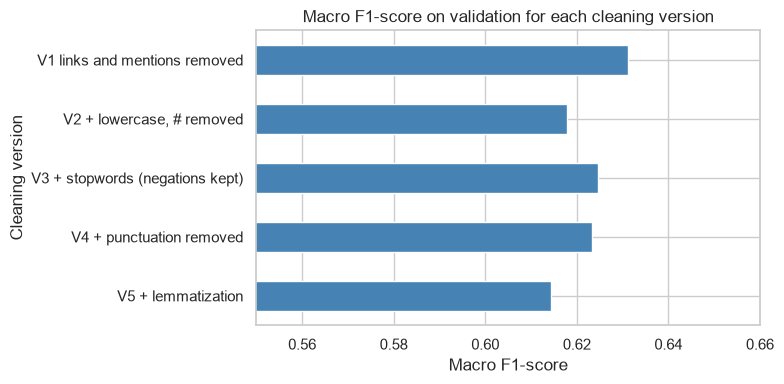

In [19]:
# Bar plot of the macro F1-score of each version
plt.figure(figsize=(8, 4))
results["f1_macro"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.title("Macro F1-score on validation for each cleaning version")
plt.xlabel("Macro F1-score")
plt.ylabel("Cleaning version")
plt.xlim(0.55, 0.66)
plt.tight_layout()
plt.show()

Version V1 (only links and mentions removed) gets the best macro F1-score on the validation split (0.631).
Lowercasing and removing the `#` sign (V2) lowers the score (0.618), and the next steps (stopwords, punctuation, lemmatization) do not improve it: the scores stay between 0.614 and 0.625.
The differences are small (the validation split has only 955 tweets, so part of them may be due to chance), but no cleaning step shows a real gain.

**Chosen version:** V1. Links and mentions are noise without information, and we keep everything else (capital letters, punctuation such as `!!!` or `...`, hashtag words, emojis, negations)
because these elements may carry the tone of an ironic tweet and the experiment does not show that removing them helps.

### 2.3 Creating the `text_clean` column

In [20]:
# Pick the version with the best macro F1-score on validation
best = results["f1_macro"].idxmax()
final_config = versions[best]

print("Chosen version:", best)
print(final_config)

Chosen version: V1 links and mentions removed
{'remove_links': True, 'remove_mentions': True, 'hashtags': 'keep', 'lowercase': False, 'remove_stopwords': False, 'remove_punct': False, 'lemmatize': False}


In [21]:
# Apply the same cleaning to the three splits
for df in (train, val, test):
    df["text_clean"] = df["text"].apply(lambda t: clean_text(t, **final_config))

train[["text", "text_clean", "label"]].head(10)

,text,text_clean,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵","look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",0
2,Now I remember why I buy books online @user #servicewithasmile,Now I remember why I buy books online #servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,So is he banded from wearing the clothes? #Karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!","Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,on stage at #flzjingleball at the in #Tampa #iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,1
8,Halfway thorough my workday ... Woooo,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,1


A cleaning step can leave an empty text (for example a tweet that only contains mentions), which would break the vectorization later.

In [22]:
# Count the empty texts after cleaning
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name, ":", (df["text_clean"].str.strip() == "").sum(), "empty text(s)")

train : 0 empty text(s)
val : 1 empty text(s)
test : 0 empty text(s)


For these tweets we keep the original text in lowercase.

In [23]:
# Replace each empty text_clean by the original text in lowercase
for df in (train, val, test):
    empty = df["text_clean"].str.strip() == ""
    df.loc[empty, "text_clean"] = df.loc[empty, "text"].str.lower().str.strip()

# Check that nothing is empty anymore
for name, df in [("train", train), ("val", val), ("test", test)]:
    print(name, ":", (df["text_clean"].str.strip() == "").sum(), "empty text(s)")

train : 0 empty text(s)
val : 0 empty text(s)
test : 0 empty text(s)


In [24]:
# Average number of words before and after cleaning
print("Before:", train["text"].str.split().str.len().mean().round(1), "words on average")
print("After :", train["text_clean"].str.split().str.len().mean().round(1), "words on average")

Before: 13.5 words on average
After : 12.9 words on average


### 2.4 Saving the cleaned files

In [25]:
# Save the three cleaned splits (the other members of the group use these files)
columns = ["text", "text_clean", "label"]

train[columns].to_csv(PROCESSED_DIR / "train.csv", index=False)
val[columns].to_csv(PROCESSED_DIR / "validation.csv", index=False)
test[columns].to_csv(PROCESSED_DIR / "test.csv", index=False)

print("Files saved in", PROCESSED_DIR)

Files saved in C:\Users\Mrabet manar\Documents\irony-detection\data\processed


In [26]:
# Read the files back like the other members will (plain pd.read_csv) and check for missing text_clean
for file in ["train", "validation", "test"]:
    d = pd.read_csv(PROCESSED_DIR / (file + ".csv"))
    print(file, d.shape, "| missing text_clean:", d["text_clean"].isna().sum())

train (2859, 3) | missing text_clean: 0
validation (955, 3) | missing text_clean: 0
test (784, 3) | missing text_clean: 0


---

# Part 2 — Vectorization, Naive Bayes & Logistic Regression

*(source: `notebooks/02_nb_logreg.ipynb`)*

## 02 - Vectorization & Naive Bayes & Logistic Regression (B)

In [1]:
import sys
sys.path.append("..")
from src.evaluate import evaluate, save_results
from src.config import RESULTS

### Preparation

In [2]:
import pandas as pd
from src.config import *
from src.model import build_pipeline

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import cross_val_score
from matplotlib import pyplot as plt

METRICS_CSV = RESULTS / "metrics_B.csv"
from sklearn.naive_bayes import MultinomialNB, ComplementNB




### Loading cleaned data

In [3]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
val = pd.read_csv(PROCESSED_DIR / "validation.csv")

train["text_clean"] = train["text_clean"].fillna("")
val["text_clean"] = val["text_clean"].fillna("")

X_train, y_train = train["text_clean"], train["label"]
X_val, y_val = val["text_clean"], val["label"]

print("train :", X_train.shape, "| val :", X_val.shape)

train : (2859,) | val : (955,)


## 1. Vectorization

### 1.1 create the TF-IDF vectorizer (the object that transforms text into numbers)

In [4]:
TOKEN_PATTERN = r"[\w']+|[^\w\s]"
vec = TfidfVectorizer(token_pattern=TOKEN_PATTERN, lowercase=False)
M_train = vec.fit_transform(X_train)     # fit to the train ONLY
M_val = vec.transform(X_val)

print("Matrice train :", M_train.shape)
print("Matrice val   :", M_val.shape)
print("Part de cases non nulles :", round(M_train.nnz / (M_train.shape[0] * M_train.shape[1]) * 100, 3), "%")

Matrice train : (2859, 9670)
Matrice val   : (955, 9670)
Part de cases non nulles : 0.148 %


### 1.2 Comparison of configurations
Why Logistic Regression? To compare the cleaning versions and vectorizer settings, we needed one fixed, simple model, so that any change in score comes from the preprocessing and not from the model. Logistic Regression is a strong baseline for text classification on sparse TF-IDF features, it is fast enough to test many configurations, and it is interpretable: it learns one weight per word, which lets us show the words that push towards irony or non-irony. It also serves as the reference against which the other models are compared.

,n_features,accuracy_val,f1_macro_val,f1_macro_cv_train
"BoW words (1,1)",9670,0.6230,0.6227,0.6205
"TF-IDF words (1,1)",9670,0.6325,0.6323,0.6126
"TF-IDF words (1,1) + sublinear_tf",9670,0.6220,0.6217,0.6152
"TF-IDF words (1,2)",41106,0.6283,0.6281,0.6142
"TF-IDF words (1,2) + min_df=2",6976,0.6346,0.6345,0.6192
"TF-IDF words (1,2) + min_df=2 + sublinear_tf",6976,0.6283,0.6281,0.6184
"TF-IDF char_wb (2,5)",83517,0.6272,0.6272,0.6252
"TF-IDF char_wb (2,5) + sublinear_tf",83517,0.6178,0.6178,0.6265
"TF-IDF char_wb (2,5) + min_df=2 + sublinear_tf",32923,0.6199,0.6196,0.6234


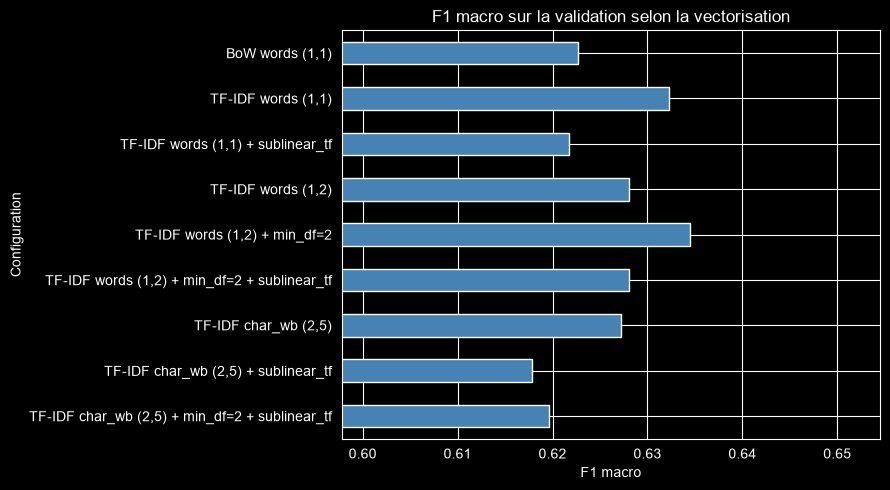

In [5]:
def faire_pipeline(vectorizer):
    return Pipeline([
        ("tfidf", vectorizer),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

words = dict(token_pattern=TOKEN_PATTERN, lowercase=False)
chars = dict(analyzer="char_wb", ngram_range=(2, 5), lowercase=False)

configs = {
    "BoW words (1,1)": CountVectorizer(**words),
    "TF-IDF words (1,1)": TfidfVectorizer(**words),
    "TF-IDF words (1,1) + sublinear_tf": TfidfVectorizer(**words, sublinear_tf=True),
    "TF-IDF words (1,2)": TfidfVectorizer(**words, ngram_range=(1, 2)),
    "TF-IDF words (1,2) + min_df=2": TfidfVectorizer(**words, ngram_range=(1, 2), min_df=2),
    "TF-IDF words (1,2) + min_df=2 + sublinear_tf": TfidfVectorizer(**words, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    "TF-IDF char_wb (2,5)": TfidfVectorizer(**chars),
    "TF-IDF char_wb (2,5) + sublinear_tf": TfidfVectorizer(**chars, sublinear_tf=True),
    "TF-IDF char_wb (2,5) + min_df=2 + sublinear_tf": TfidfVectorizer(**chars, min_df=2, sublinear_tf=True),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def tester(vectorizer):
    modele = faire_pipeline(vectorizer)
    modele.fit(X_train, y_train)
    pred = modele.predict(X_val)

    cv_f1 = cross_val_score(faire_pipeline(vectorizer), X_train, y_train, cv=cv, scoring="f1_macro").mean()

    return {
        "n_features": len(modele.named_steps["tfidf"].get_feature_names_out()),
        "accuracy_val": accuracy_score(y_val, pred),
        "f1_macro_val": f1_score(y_val, pred, average="macro"),
        "f1_macro_cv_train": cv_f1,
    }
resultats = pd.DataFrame({nom: tester(v) for nom, v in configs.items()}).T
resultats["n_features"] = resultats["n_features"].astype(int)
resultats = resultats.round(4)
display(resultats)

plt.figure(figsize=(9, 5))
resultats["f1_macro_val"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.title("F1 macro sur la validation selon la vectorisation")
plt.xlabel("F1 macro")
plt.ylabel("Configuration")
plt.xlim(resultats["f1_macro_val"].min() - 0.02, resultats["f1_macro_val"].max() + 0.02)
plt.tight_layout()
plt.show()

We keep TF-IDF words (1,2) + min_df=2, which has the highest validation macro-F1 (about 0.634).
However, the differences between configurations are small (all scores fall between about 0.62 and 0.635), which is within the noise we expect on a validation set of 955 tweets. So the score alone does not prove that this configuration is better than the others.
We keep it for practical reasons: bigrams can capture short phrases such as "not happy", min_df=2 removes words that appear in only one tweet, and word-level features stay easy to interpret (we use them to look at the top words later). Character n-grams did not give any improvement.

### 1.3 Configuration retenue

In [6]:
#Finds the name of the configuration with the highest f1_macro_val in the results table
meilleure = resultats["f1_macro_val"].idxmax()
print("Configuration retenue :", meilleure)
print(resultats.loc[meilleure])
print()
print(configs[meilleure].get_params(deep=False))

Configuration retenue : TF-IDF words (1,2) + min_df=2
n_features           6976.0000
accuracy_val            0.6346
f1_macro_val            0.6345
f1_macro_cv_train       0.6192
Name: TF-IDF words (1,2) + min_df=2, dtype: float64

{'analyzer': 'word', 'binary': False, 'decode_error': 'strict', 'dtype': <class 'numpy.float64'>, 'encoding': 'utf-8', 'input': 'content', 'lowercase': False, 'max_df': 1.0, 'max_features': None, 'min_df': 2, 'ngram_range': (1, 2), 'norm': 'l2', 'preprocessor': None, 'smooth_idf': True, 'stop_words': None, 'strip_accents': None, 'sublinear_tf': False, 'token_pattern': "[\\w']+|[^\\w\\s]", 'tokenizer': None, 'use_idf': True, 'vocabulary': None}


### Verification

In [7]:
modele_final = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
modele_final.fit(X_train, y_train)
pred = modele_final.predict(X_val)

print("F1 macro (validation) :", round(f1_score(y_val, pred, average="macro"), 4))
print("Table value           :", resultats.loc[meilleure, "f1_macro_val"])

F1 macro (validation) : 0.6345
Table value           : 0.6345


## 2. Naive Bayes

**Idea:** Naive Bayes uses how often each word appears in ironic vs non-ironic tweets, assuming the words are independent. It is the classic, very fast baseline for text.

### 2.1 Tuning alpha (smoothing)

Best parameters: {'clf': MultinomialNB(), 'clf__alpha': 2.0}
Best CV macro-F1: 0.6209


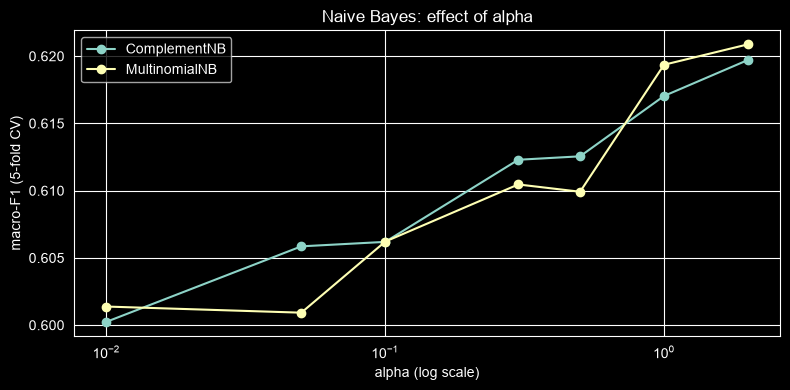

In [8]:
nb_grid = GridSearchCV(
    build_pipeline(MultinomialNB()),
    param_grid={
        "clf": [MultinomialNB(), ComplementNB()],
        "clf__alpha": [0.01, 0.05, 0.1, 0.3, 0.5, 1.0, 2.0],
    },
    cv=cv,
    scoring="f1_macro",
)
nb_grid.fit(X_train, y_train)

print("Best parameters:", nb_grid.best_params_)
print("Best CV macro-F1:", round(nb_grid.best_score_, 4))

nb_cv = pd.DataFrame(nb_grid.cv_results_)
nb_cv["model"] = nb_cv["param_clf"].astype(str).str.replace("()", "", regex=False)
nb_cv = nb_cv.rename(columns={"param_clf__alpha": "alpha", "mean_test_score": "f1_macro_cv", "std_test_score": "cv_std"})

plt.figure(figsize=(8, 4))
for name, group in nb_cv.groupby("model"):
    plt.plot(group["alpha"], group["f1_macro_cv"], marker="o", label=name)
plt.xscale("log")
plt.xlabel("alpha (log scale)")
plt.ylabel("macro-F1 (5-fold CV)")
plt.title("Naive Bayes: effect of alpha")
plt.legend()
plt.tight_layout()
plt.show()

### 2.2 Best Naitive Bayes

---MultinomialNB---
              precision    recall  f1-score   support

   non_irony      0.664     0.597     0.629       499
       irony      0.603     0.669     0.634       456

    accuracy                          0.631       955
   macro avg      0.633     0.633     0.631       955
weighted avg      0.635     0.631     0.631       955



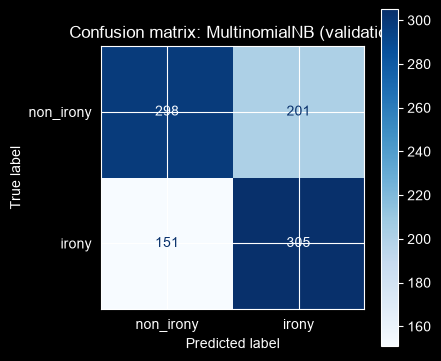

In [9]:
nb_best = nb_grid.best_estimator_          # already refitted on the whole training set
pred_nb = nb_best.predict(X_val)

nb_name = type(nb_best.named_steps["clf"]).__name__
nb_metrics = evaluate(nb_name, y_val, pred_nb)
save_results(nb_metrics, METRICS_CSV, **nb_grid.best_params_)

## 3.Logistic Regression

**Idea:** Logistic Regression learns **one weight per word**: positive weights push towards irony, negative weights towards non-irony; the sum decides the class. It is usually the strongest classical model for text, and fully interpretable.

### 3.1 Tuning "C" the inverse of regularization strength

In [10]:
lr_grid = GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    param_grid={
        "clf__C": [0.1, 0.3, 1, 3, 10],
        "clf__class_weight": [None, "balanced"],
    },
    cv=cv,
    scoring="f1_macro",
)
lr_grid.fit(X_train, y_train)

print("Best parameters:", lr_grid.best_params_)
print("Best CV macro-F1:", round(lr_grid.best_score_, 4))

pd.DataFrame(lr_grid.cv_results_)[
    ["param_clf__C", "param_clf__class_weight", "mean_test_score", "std_test_score"]
].round(4)


Best parameters: {'clf__C': 3, 'clf__class_weight': None}
Best CV macro-F1: 0.6226


,param_clf__C,param_clf__class_weight,mean_test_score,std_test_score
0,0.1,NaN,0.5803,0.0099
1,0.1,balanced,0.5912,0.0132
2,0.3,NaN,0.6014,0.0180
3,0.3,balanced,0.6033,0.0185
4,1.0,NaN,0.6192,0.0232
5,1.0,balanced,0.6174,0.0245
6,3.0,NaN,0.6226,0.0194
7,3.0,balanced,0.6217,0.0172
8,10.0,NaN,0.6132,0.0193
9,10.0,balanced,0.6143,0.0212


### 3.2 Evaluation of the best Logistic Regression on validation

---LogisticRegression---
              precision    recall  f1-score   support

   non_irony      0.668     0.645     0.656       499
       irony      0.626     0.649     0.637       456

    accuracy                          0.647       955
   macro avg      0.647     0.647     0.647       955
weighted avg      0.648     0.647     0.647       955



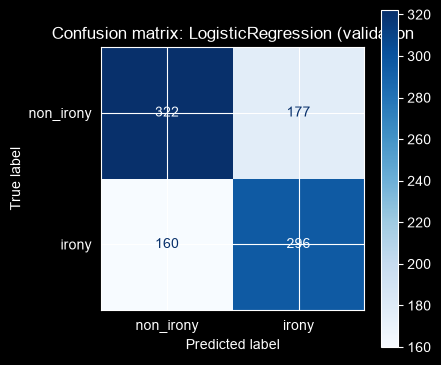

In [11]:
lr_best= lr_grid.best_estimator_
pred_lr=lr_grid.predict(X_val)

lr_metrics=evaluate("LogisticRegression", y_val, pred_lr)
save_results(lr_metrics,METRICS_CSV,**lr_grid.best_params_)

### 3.3 Which words push towards irony?

Logistic Regression gives one weight to each word (or pair of words). Positive weights push a tweet towards irony, negative weights towards non-irony. We plot the 20 strongest of each side.

In [ ]:
words = lr_best.named_steps["tfidf"].get_feature_names_out()
weights = lr_best.named_steps["clf"].coef_[0]

coef = pd.Series(weights, index=words).sort_values()
top_irony = coef.tail(20)
top_non_irony = coef.head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
top_irony.plot(kind="barh", ax=axes[0], color="indianred")
axes[0].set_title("Top 20 words → irony")
axes[0].set_xlabel("weight")
top_non_irony.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Top 20 words → non_irony")
axes[1].set_xlabel("weight")
plt.tight_layout()
plt.show()

**Observation.** The words that push towards irony are mostly **positive words** (*great, I love, fun, Yay, thanks for*) and words about **unpleasant situations** (*Monday, test*), plus the 😒 emoji. This is the classic pattern of verbal irony: saying something positive about something negative ("I love Mondays"). The model only sees words, so it cannot tell a sincere "I love" from an ironic one — which limits all bag-of-words models.

Surprisingly, *not* pushes strongly towards **non**-irony. This is a side effect of how the dataset was built: the hashtag **#not** was deleted from ironic tweets, so the word "not" survives mostly in non-ironic tweets.

## 4. Conclusion

| Model | Settings (5-fold CV on train) | CV macro-F1 | Validation macro-F1 |
|---|---|---|---|
| Multinomial Naive Bayes | alpha = 2.0 | 0.621 | 0.631 |
| **Logistic Regression** | C = 3, no class weight | 0.623 | **0.647** |

- **Vectorization:** the nine configurations tested are within about 0.015 of each other, less than the cross-validation noise (std ≈ 0.02). We kept TF-IDF on words, unigrams + bigrams, `min_df=2`: as good as the others, simpler, and interpretable.
- **Both models are close.** Logistic Regression is slightly better on validation, and it is fully interpretable: its weights show which words signal irony.
- **Limit:** both models only count words. Irony depends on tone and context ("I love Mondays"), which a bag of words cannot see. This motivates the transformer of notebook 04.
- The test set is not used here: all models are evaluated on it together in notebook 05.

---

# Part 3 — SVM, Random Forest & KNN

*(source: `notebooks/03_svm_rf_knn.ipynb`)*

## 03 - SVM, Random Forest & KNN (C)

## 1. Preparation

### 1.1 Imports

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PROCESSED_DIR, RESULTS, RANDOM_STATE, TEXT_COL
from src.evaluate import evaluate, save_results
from src.model import build_pipeline

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score



### 1.2 Loading the data

In [2]:
# Load cleaned datasets
train = pd.read_csv(PROCESSED_DIR / "train.csv")
val = pd.read_csv(PROCESSED_DIR / "validation.csv")

# A cleaned tweet can be empty; it is read back as NaN, which would crash TF-IDF
train[TEXT_COL] = train[TEXT_COL].fillna("")
val[TEXT_COL] = val[TEXT_COL].fillna("")

# Separate features and labels
X_train, y_train = train[TEXT_COL], train["label"]
X_val, y_val = val[TEXT_COL], val["label"]

# Check dimensions
print("Training:", X_train.shape)
print("Validation:", X_val.shape)

# cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


Training: (2859,)
Validation: (955,)


## 2. SVM

### 2.1 Baseline: SVM with default settings

Before tuning anything, we train **one simple SVM with its default settings** through the shared pipeline (TF-IDF + model).

We only test the linear version: for sparse, high-dimensional text, a straight boundary is the standard choice, and it is much faster than a curved (rbf) kernel.

---SVM baseline---
              precision    recall  f1-score   support

   non_irony      0.637     0.627     0.632       499
       irony      0.599     0.610     0.604       456

    accuracy                          0.619       955
   macro avg      0.618     0.618     0.618       955
weighted avg      0.619     0.619     0.619       955



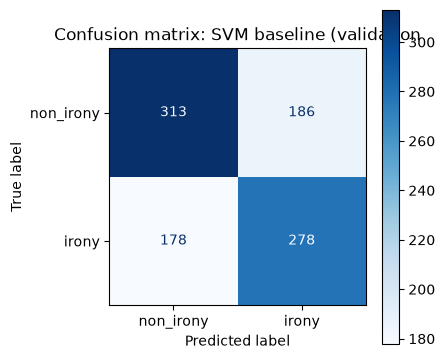

Number of TF-IDF features: 6976


{'model': 'SVM baseline',
 'split': 'validation',
 'accuracy': 0.618848167539267,
 'precision': 0.5991379310344828,
 'recall': 0.6096491228070176,
 'f1': 0.6043478260869565,
 'f1_macro': 0.6183355292050944}

In [3]:

# Shared pipeline = TF-IDF vectorizer + a default SVM
baseline = build_pipeline(LinearSVC(random_state=RANDOM_STATE))

# Learn on the training tweets only (the pipeline fits TF-IDF on train too, so no leakage)
baseline.fit(X_train, y_train)

# Predict the validation tweets and score them with the team's evaluate()
y_pred = baseline.predict(X_val)
metrics_base = evaluate("SVM baseline", y_val, y_pred, save_fig=False)

# How many numbers (features) describe each tweet after TF-IDF?
n_features = len(baseline.named_steps["tfidf"].get_feature_names_out())
print("Number of TF-IDF features:", n_features)
metrics_base

### 2.2 Tuning the SVM with GridSearchCV

The SVM has one important setting (a **hyperparameter**): `C`, which controls how strict the model is on the training tweets.
- **small C** → the model accepts some mistakes on train and keeps a smooth, simple boundary (less overfitting)
- **large C** → the model tries hard to classify every training tweet correctly (risk of overfitting)

We test 7 values of `C` with `GridSearchCV`: for each value, it trains and scores the pipeline with **5-fold cross-validation on the training set only**, using **macro-F1**.
The best `C` is then evaluated once on the validation split.



Best parameters: {'clf__C': 0.5}
Best CV macro-F1: 0.6175


,param_clf__C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.5736,0.0116,7
1,0.10,0.6167,0.0225,2
2,0.50,0.6175,0.0177,1
3,1.00,0.6105,0.0197,3
4,5.00,0.5926,0.0173,4
5,10.00,0.5874,0.0184,5
6,100.00,0.5803,0.0164,6


---SVM tuned---
              precision    recall  f1-score   support

   non_irony      0.642     0.615     0.628       499
       irony      0.597     0.625     0.611       456

    accuracy                          0.620       955
   macro avg      0.620     0.620     0.620       955
weighted avg      0.621     0.620     0.620       955



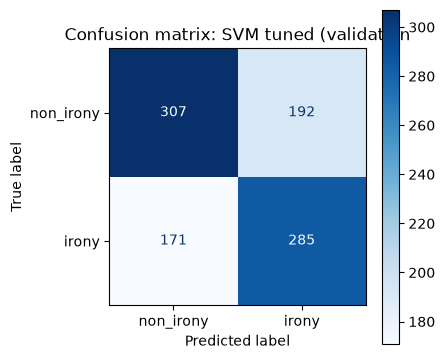

In [4]:

# Same shared pipeline; max_iter is raised so that large values of C can converge
pipe_svm = build_pipeline(LinearSVC(max_iter=10000, random_state=RANDOM_STATE))

# Values of C to try 
param_grid_svm = {"clf__C": [0.01, 0.1, 0.5, 1, 5, 10, 100]}

# 5-fold cross-validation on TRAIN, scored with macro-F1 
grid_svm = GridSearchCV(pipe_svm, param_grid_svm, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_svm.fit(X_train, y_train)

print("Best parameters:", grid_svm.best_params_)
print("Best CV macro-F1:", round(grid_svm.best_score_, 4))

# Table of all the tested values
cv_svm = pd.DataFrame(grid_svm.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score", "rank_test_score"]]
display(cv_svm.round(4))

# Evaluate the best SVM on the validation split
y_pred_svm = grid_svm.predict(X_val)
metrics_svm = evaluate("SVM tuned", y_val, y_pred_svm)

### 2.3 Overfitting check


In [5]:

train_f1_svm = f1_score(y_train, grid_svm.predict(X_train), average="macro")
val_f1_svm = metrics_svm["f1_macro"]

print("Train macro-F1     :", round(train_f1_svm, 4))
print("Validation macro-F1:", round(val_f1_svm, 4))
print("Gap                :", round(train_f1_svm - val_f1_svm, 4))

Train macro-F1     : 0.9755
Validation macro-F1: 0.6197
Gap                : 0.3558


The SVM scores 0.976 on the training tweets but only 0.620 on validation (gap 0.356). We have 6,976 features for only 2,859 tweets, so a straight-line boundary can almost always separate the training tweets perfectly. The gap shows that the model memorizes the training data. It does not mean that C was badly chosen, since C was chosen by cross-validation.

## 3. Random Forest

A `Random Forest` is a group of many decision trees. Each tree asks a series of yes/no questions about the tweet (for example "does it contain the word *love*?") and votes ironic or not ironic. The forest takes the `majority vote`.
Each tree sees a random sample of the tweets and a random subset of the words at each split, so the trees make different mistakes and the vote is more reliable than a single tree.

### 3.1 Baseline with default settings

---RF baseline---
              precision    recall  f1-score   support

   non_irony      0.642     0.585     0.612       499
       irony      0.586     0.643     0.613       456

    accuracy                          0.613       955
   macro avg      0.614     0.614     0.613       955
weighted avg      0.615     0.613     0.613       955



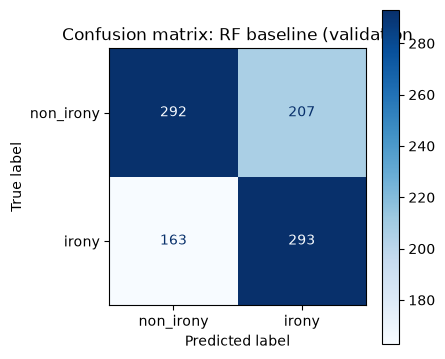

{'model': 'RF baseline',
 'split': 'validation',
 'accuracy': 0.612565445026178,
 'precision': 0.586,
 'recall': 0.6425438596491229,
 'f1': 0.6129707112970711,
 'f1_macro': 0.6125650202187662}

In [6]:

# Default Random Forest through the shared pipeline
rf_base = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
rf_base.fit(X_train, y_train)

metrics_rf_base = evaluate("RF baseline", y_val, rf_base.predict(X_val), save_fig=False)
metrics_rf_base

### 3.2 Tuning with GridSearchCV

We tune three hyperparameters (5-fold CV on train, macro-F1):
- `n_estimators`: number of trees in the forest
- `max_depth`: maximum number of questions a tree can ask in a row (`None` = no limit)
- `min_samples_leaf`: minimum number of tweets in a final leaf (larger = simpler trees, less overfitting)


In [7]:
pipe_rf = build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE))

param_grid_rf = {
    "clf__n_estimators": [100, 300],
    "clf__max_depth": [None, 50],
    "clf__min_samples_leaf": [1, 3],
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best CV macro-F1:", round(grid_rf.best_score_, 4))

Best parameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
Best CV macro-F1: 0.6302


### 3.3 All tested combinations

`mean_test_score` is the average macro-F1 over the 5 folds and `std_test_score` is how much the 5 scores vary.
A gap between two rows that is smaller than the std is probably just luck.

In [8]:
cv_rf = pd.DataFrame(grid_rf.cv_results_)[[
    "param_clf__n_estimators", "param_clf__max_depth", "param_clf__min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score"]]

display(cv_rf.sort_values("rank_test_score").round(4))

,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
0,100,None,1,0.6302,0.0154,1
2,100,None,3,0.6232,0.0232,2
6,100,50,3,0.6221,0.0222,3
5,300,50,1,0.6208,0.0143,4
7,300,50,3,0.6202,0.0227,5
4,100,50,1,0.6198,0.0054,6
1,300,None,1,0.6192,0.0150,7
3,300,None,3,0.6190,0.0163,8


### 3.4 Evaluation of the best forest on validation

---Random Forest tuned---
              precision    recall  f1-score   support

   non_irony      0.642     0.585     0.612       499
       irony      0.586     0.643     0.613       456

    accuracy                          0.613       955
   macro avg      0.614     0.614     0.613       955
weighted avg      0.615     0.613     0.613       955



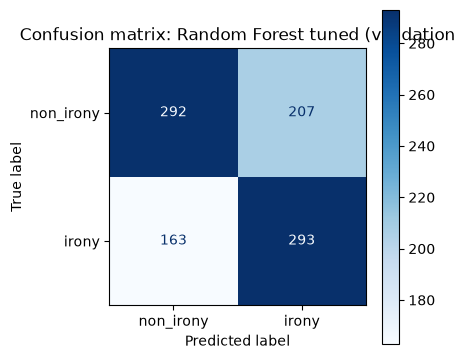

In [9]:
y_pred_rf = grid_rf.predict(X_val)
metrics_rf = evaluate("Random Forest tuned", y_val, y_pred_rf)

### 3.5 Overfitting check


In [10]:
train_f1 = f1_score(y_train, grid_rf.predict(X_train), average="macro")
val_f1 = metrics_rf["f1_macro"]

print("Train macro-F1     :", round(train_f1, 4))
print("Validation macro-F1:", round(val_f1, 4))
print("Gap                :", round(train_f1 - val_f1, 4))

Train macro-F1     : 0.9997
Validation macro-F1: 0.6126
Gap                : 0.3871


The forest scores 0.9997 on the training tweets and 0.613 on validation (gap 0.387). With no depth limit and leaves of one tweet, every tree grows until it fits its training sample almost perfectly, and a Random Forest always scores close to perfect on data it has already seen, so the validation score is the one to trust. The best settings are also scikit-learn's defaults, so tuning did not change the model.

## 4. KNN (K-Nearest Neighbors)

KNN does not really "learn" anything. It **stores all the training tweets**, and to classify a new tweet it finds the `k` most similar training tweets (its *neighbors*) and takes the **majority vote** of their labels.
"Similar" means close in the TF-IDF space: two tweets that share many of the same (weighted) words are close.

### 4.1 Baseline with default settings

---KNN baseline---
              precision    recall  f1-score   support

   non_irony      0.703     0.194     0.305       499
       irony      0.508     0.910     0.652       456

    accuracy                          0.536       955
   macro avg      0.605     0.552     0.478       955
weighted avg      0.610     0.536     0.470       955



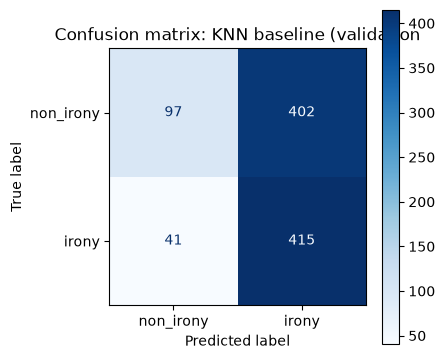

{'model': 'KNN baseline',
 'split': 'validation',
 'accuracy': 0.5361256544502618,
 'precision': 0.5079559363525091,
 'recall': 0.9100877192982456,
 'f1': 0.6520031421838177,
 'f1_macro': 0.47827786622534685}

In [11]:

# Default KNN (k = 5) through the shared pipeline
knn_base = build_pipeline(KNeighborsClassifier())
knn_base.fit(X_train, y_train)

metrics_knn_base = evaluate("KNN baseline", y_val, knn_base.predict(X_val), save_fig=False)
metrics_knn_base

### 4.2 Tuning with GridSearchCV

We tune three hyperparameters (stratified 5-fold CV on train, macro-F1):
- `n_neighbors` (k): how many neighbors vote. Small k = very sensitive to single tweets, large k = smoother but less precise.
- `weights`: `uniform` = every neighbor counts the same, `distance` = closer neighbors count more.
- `metric`: how "close" is measured. `euclidean` = straight-line distance, `cosine` = the angle between two tweets, which ignores their length. Cosine is the usual choice for text.

In [12]:
pipe_knn = build_pipeline(KNeighborsClassifier())

param_grid_knn = {
    "clf__n_neighbors": [3, 5, 11, 21, 41, 81, 91, 101],
    "clf__weights": ["uniform", "distance"],
    "clf__metric": ["euclidean", "cosine"],
}

grid_knn = GridSearchCV(pipe_knn, param_grid_knn, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_knn.fit(X_train, y_train)

print("Best parameters:", grid_knn.best_params_)
print("Best CV macro-F1:", round(grid_knn.best_score_, 4))

Best parameters: {'clf__metric': 'cosine', 'clf__n_neighbors': 21, 'clf__weights': 'distance'}
Best CV macro-F1: 0.6025


### 4.3 All tested combinations

In [13]:
cv_knn = pd.DataFrame(grid_knn.cv_results_)[[
    "param_clf__n_neighbors", "param_clf__weights", "param_clf__metric",
    "mean_test_score", "std_test_score", "rank_test_score"]]

display(cv_knn.sort_values("rank_test_score").head(10).round(4))

,param_clf__n_neighbors,param_clf__weights,param_clf__metric,mean_test_score,std_test_score,rank_test_score
23,21,distance,cosine,0.6025,0.0007,1
22,21,uniform,cosine,0.6018,0.0044,2
24,41,uniform,cosine,0.6014,0.0109,3
25,41,distance,cosine,0.6013,0.0098,4
8,41,uniform,euclidean,0.6000,0.0110,5
9,41,distance,euclidean,0.5996,0.0107,6
15,101,distance,euclidean,0.5980,0.0207,7
31,101,distance,cosine,0.5967,0.0229,8
29,91,distance,cosine,0.5965,0.0177,9
14,101,uniform,euclidean,0.5954,0.0237,10


### 4.4 Evaluation of the best KNN on validation

---KNN tuned---
              precision    recall  f1-score   support

   non_irony      0.653     0.677     0.665       499
       irony      0.632     0.605     0.618       456

    accuracy                          0.643       955
   macro avg      0.642     0.641     0.641       955
weighted avg      0.643     0.643     0.642       955



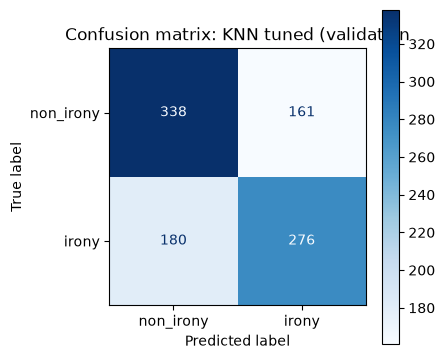

In [14]:
y_pred_knn = grid_knn.predict(X_val)
metrics_knn = evaluate("KNN tuned", y_val, y_pred_knn)

### 4.5 Overfitting check


In [15]:
train_f1_knn = f1_score(y_train, grid_knn.predict(X_train), average="macro")
val_f1_knn = metrics_knn["f1_macro"]

print("Train macro-F1     :", round(train_f1_knn, 4))
print("Validation macro-F1:", round(val_f1_knn, 4))
print("Gap                :", round(train_f1_knn - val_f1_knn, 4))

Train macro-F1     : 0.999
Validation macro-F1: 0.6414
Gap                : 0.3575


KNN scores 0.999 on the training tweets and 0.641 on validation (gap 0.358). This large gap is partly built into the method: with `weights="distance"`, a training tweet is its own nearest neighbor at distance 0, so it always predicts itself correctly. The train score is therefore perfect by construction and says little about overfitting. The validation score is the one to trust.

## 6. Saving the results

In [16]:
csv_path = RESULTS / "metrics_C.csv"

save_results(metrics_svm, csv_path, **grid_svm.best_params_)
save_results(metrics_rf, csv_path, **grid_rf.best_params_)
save_results(metrics_knn, csv_path, **grid_knn.best_params_)

pd.read_csv(csv_path)

,model,split,accuracy,precision,recall,f1,f1_macro,params
0,SVM tuned,validation,0.619895,0.597484,0.625000,0.610932,0.619693,clf__C=0.5
1,Random Forest tuned,validation,0.612565,0.586000,0.642544,0.612971,0.612565,clf__max_depth=None; clf__min_samples_leaf=1; ...
2,KNN tuned,validation,0.642932,0.631579,0.605263,0.618141,0.641421,clf__metric=cosine; clf__n_neighbors=21; clf__...


### Conclusion

On validation the three models end very close to each other (KNN 0.641, SVM 0.620, Random Forest 0.613 macro-F1), and the order is reversed in cross-validation, so none of them is clearly better.

The Random Forest and KNN struggle on TF-IDF text. Each tweet uses only a tiny fraction of the thousands of features, so a tree has little to split on, and tweets that share words share a topic, not necessarily the same tone, so a single neighbor is a weak clue. The SVM copes better because it adds up the weights of many words.

All three only count words, while irony lives in the tone, so none of them gets close to the best 2018 system (0.71).

---

# Part 4 — Transformer fine-tuning (Twitter-RoBERTa)

*(source: `notebooks/04_transformer.ipynb`)*

## 04 — Transformer fine-tuning (Task D)

**Project:** Irony detection in tweets — TweetEval `irony` (SemEval-2018 Task 3)
**Goal of this notebook:** fine-tune a pre-trained transformer (BERT family) to classify tweets as **ironic (1)** or **not ironic (0)**, and compare it with the classical models (TF-IDF + NB / LogReg / SVM / RF / KNN) of the other notebooks.
**Author:** Mohamed Chaker Iben Hadj Amor
**Tools:** Python 3.12 · PyTorch (CUDA, RTX 5060 Ti) · Hugging Face Transformers & Datasets · pandas · scikit-learn

**Why a transformer?** TF-IDF models only count words: they lose word order and context. Irony lives precisely in the *contrast* between the words and the situation ("I *love* waiting 2 hours at the bank"). A transformer is pre-trained on billions of sentences and reads each word **in context**, so it should capture this contrast better.

**Plan**
1. Setup and GPU check
2. Loading the data
3. Data quality: corrupted rows
4. Hugging Face dataset format
5. Tokenization
6. Model, metrics and training (DistilBERT)
7. Results so far and next steps

### 1. Setup and GPU check

The first cell lets the notebook find the shared `src/` folder (one level up). The imports from `src/` are commented out for now: those files are written by other team members and are still empty.

Fine-tuning a transformer is heavy computation, so we first make sure **PyTorch can use the NVIDIA GPU**. Checking `torch.cuda.is_available()` is not enough: we also multiply two random 1000×1000 matrices **on the GPU**, which proves the GPU really computes.

**Sanity check of the result:** each entry of `x @ x` is a sum of 1000 products of two random numbers in [0, 1). Their average is 0.5 × 0.5 = 0.25, so each entry ≈ 250, and the sum of the 1,000,000 entries ≈ **250,000,000** — which is what we get.

In [1]:
import sys
sys.path.append("..")

#from src.config import *
#from src.data import load_split
#from src.cleaning import clean_text
#from src.evaluate import evaluate, save_results

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0))

x = torch.rand(1000, 1000, device="cuda")
y = x @ x
print("Result:", y.sum().item())

PyTorch version: 2.15.0+cu132
CUDA available: True
GPU name: NVIDIA GeForce RTX 5060 Ti
Result: 249688944.0


### 2. Loading the data

The official TweetEval files store **text and labels in separate files**, one tweet per line: line *N* of `train_text.txt` goes with line *N* of `train_labels.txt`.

Choices made in `load_raw_split()`:
- **Read line by line, not with `pd.read_csv`**: hundreds of tweets contain commas and quotes, which `read_csv` would interpret as column separators and break the tweets apart.
- **`encoding="utf-8"`**: tweets contain emojis and special characters.
- **`.splitlines()`**: splits on line breaks without creating an empty extra row at the end of the file.
- **`assert`**: if a text file and its labels file ever had different lengths, every tweet after the mismatch would silently get the wrong label. The assert turns this into a clear error.

We check that we get the official sizes: **2862 / 955 / 784** tweets.

In [3]:
import pandas as pd

DATA_DIR = "../data/raw"

def load_raw_split(split):
    """Read one split ("train", "val" or "test") of TweetEval irony into a DataFrame."""
    with open(f"{DATA_DIR}/{split}_text.txt", encoding="utf-8") as f:
        texts = f.read().splitlines()

    with open(f"{DATA_DIR}/{split}_labels.txt", encoding="utf-8") as f:
        labels = [int(line) for line in f.read().splitlines()]

    assert len(texts) == len(labels), f"{split}: {len(texts)} texts but {len(labels)} labels"

    return pd.DataFrame({"text": texts, "label": labels})


train_df = load_raw_split("train")
val_df = load_raw_split("val")
test_df = load_raw_split("test")

print("train:", train_df.shape)
print("val:  ", val_df.shape)
print("test: ", test_df.shape)

train: (2862, 2)
val:   (955, 2)
test:  (784, 2)


In [4]:
train_df.head()

,text,label
0,seeing ppl walking w/ crutches makes me really...,1
1,"look for the girl with the broken smile, ask h...",0
2,Now I remember why I buy books online @user #s...,1
3,@user @user So is he banded from wearing the c...,1
4,Just found out there are Etch A Sketch apps. ...,1


### 3. Data quality: corrupted rows in the training set

Looking at the data before training, we noticed user mentions are already anonymized as `@user` and hashtags are kept.

While measuring tweet lengths, we found that the longest training "tweet" was in fact **about ten tweets merged into one line**, containing pieces of the original competition file: tweet IDs and **their own labels**, separated by tab characters (`\t`). Such a row has a single label while containing both ironic and non-ironic tweets, so **its label is unreliable**.

Searching all splits for tab characters:

| Split | Corrupted rows |
|---|---|
| train | **3** (1000, 329 and 249 characters long) |
| validation | 0 |
| test | 0 |

We **remove these 3 rows from the training set only** (2862 → **2859**). This is 0.1% of the data, so it doesn't change the class balance. The test set is clean and is never modified.

`reset_index(drop=True)` renumbers the rows after the removal; without it, the conversion to the Hugging Face format would add a useless extra index column.

In [5]:
corrupted = train_df["text"].str.contains("\t")

print("Corrupted rows found:", corrupted.sum())
print(train_df.loc[corrupted, "text"].str.len())

train_df = train_df[~corrupted].reset_index(drop=True)
print("train after removal:", train_df.shape)

Corrupted rows found: 3
1295    1000
1753     329
2773     249
Name: text, dtype: int64
train after removal: (2859, 2)


#### 3.2 A hidden label leak: extra spaces

The ironic tweets were collected with the hashtags `#not`, `#sarcasm` and `#irony`, which the dataset authors deleted from the text afterwards. Deleting a word but not the space around it leaves **extra spaces**, typically at the end of the tweet. Non-ironic tweets were never edited, so they rarely have them.

This is invisible to the eye but very visible to some models: RoBERTa's tokenizer encodes spaces as tokens, so a model can learn *"double space at the end → ironic"* instead of learning irony. DistilBERT's tokenizer (like TF-IDF) ignores whitespace, which is why it was not affected.

We measure it in each split, then **normalize the whitespace** (one single space between words, none at the ends) in all three splits. This only changes spaces, never words, punctuation, capitals or emojis.

In [6]:
for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    share = df.groupby("label")["text"].apply(lambda s: s.str.endswith("  ").mean() * 100).round(1)
    print(f"{name:10} | ends with 2+ spaces -> non_irony: {share[0]:5.1f}%   irony: {share[1]:5.1f}%")

for df in (train_df, val_df, test_df):
    df["text"] = df["text"].str.split().str.join(" ")

print("\nAfter normalization, tweets ending with a space:",
      sum(df["text"].str.endswith(" ").sum() for df in (train_df, val_df, test_df)))

train      | ends with 2+ spaces -> non_irony:   3.3%   irony:  63.7%
validation | ends with 2+ spaces -> non_irony:   2.6%   irony:  56.6%
test       | ends with 2+ spaces -> non_irony:   0.0%   irony:   0.0%

After normalization, tweets ending with a space: 0


### 4. Hugging Face dataset format

The tokenizer and the `Trainer` work on Hugging Face `Dataset` objects, not on pandas DataFrames. We convert each split and group the three of them in a `DatasetDict`, so that later **one** `.map()` call can tokenize all splits at once. The split is named `validation`, following the Hugging Face convention.

The first training example already shows **verbal irony**: *"really excited for the next 3 weeks"* — said by someone on crutches. Positive words, negative situation, label 1.

In [7]:
from datasets import Dataset, DatasetDict

ds = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})

print(ds)
print(ds["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 784
    })
})
{'text': 'seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life', 'label': 1}


### 5. Tokenization

A neural network only works with numbers. The **tokenizer** converts each tweet into a list of **token IDs**:

`"really excited for my crutches"` → `["really", "excited", "for", "my", "crut", "##ches"]` → `[2428, 7568, ...]`

Key points:
- Tokens are often **pieces of words** (subwords): rare words are split into known pieces, so the model never meets a completely unknown word.
- **Each model has its own tokenizer**, and we must use the one it was pre-trained with — otherwise the IDs mean nothing to the model.
- The tokenizer adds **special tokens** (`[CLS]` at the start, `[SEP]` at the end for BERT models).
- The **attention mask** marks real tokens (1) versus padding (0).

We start with **DistilBERT** (`distilbert-base-uncased`), a smaller, faster version of BERT, to build and debug the full pipeline.

In [8]:
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = ds["train"][0]["text"]
encoded = tokenizer(example)

print("Tweet:    ", example)
print("input_ids:", encoded["input_ids"])
print("tokens:   ", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print("attention:", encoded["attention_mask"])

Tweet:     seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life
input_ids: [101, 3773, 4903, 2140, 3788, 1059, 1013, 13675, 4904, 8376, 3084, 2033, 2428, 7568, 2005, 1996, 2279, 1017, 3134, 1997, 2026, 2166, 102]
tokens:    ['[CLS]', 'seeing', 'pp', '##l', 'walking', 'w', '/', 'cr', '##ut', '##ches', 'makes', 'me', 'really', 'excited', 'for', 'the', 'next', '3', 'weeks', 'of', 'my', 'life', '[SEP]']
attention: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


#### 5.1 Does the tokenizer keep the irony signals?

We tokenize a sarcastic sentence with two tokenizers:

| Tokenizer | Result for `"Oh GREAT, another Monday 🙂"` |
|---|---|
| DistilBERT (uncased) | `oh`, `great`, …, **`[UNK]`** |
| RoBERTa | `Oh`, `ĠGREAT`, …, **`ĠðŁĻĤ`** |

- DistilBERT-**uncased** lowercases everything: **"GREAT" (shouting) becomes "great"** (neutral).
- It doesn't know the emoji and replaces it with **`[UNK]`** (unknown): the 🙂 is lost.
- RoBERTa **keeps the capitals**, and encodes the emoji as a real token (the strange characters are the emoji's bytes; `Ġ` marks a preceding space).

**Conclusion:** DistilBERT-uncased loses two irony signals. This is why our final model will come from the **RoBERTa family**; DistilBERT is kept as a baseline for comparison.

In [9]:
roberta_tokenizer = AutoTokenizer.from_pretrained("FacebookAI/roberta-base")

test_tweet = "Oh GREAT, another Monday 🙂"

for name, tok in [("DistilBERT", tokenizer), ("RoBERTa", roberta_tokenizer)]:
    ids = tok(test_tweet)["input_ids"]
    print(f"{name:10} -> {tok.convert_ids_to_tokens(ids)}")

DistilBERT -> ['[CLS]', 'oh', 'great', ',', 'another', 'monday', '[UNK]', '[SEP]']
RoBERTa    -> ['<s>', 'Oh', 'ĠGREAT', ',', 'Ġanother', 'ĠMonday', 'ĠðŁĻĤ', '</s>']


#### 5.2 Choosing the maximum length

Every model has a maximum input length, and we need to choose `max_length`: too short cuts tweets, too long wastes memory and time. We **measure** the length in tokens of every training tweet instead of guessing:

| Statistic | Value |
|---|---|
| mean | ≈ 23 tokens |
| median | 22 |
| 99th percentile | 44 |
| max (after removing the corrupted rows) | 60 |

Before the corrupted rows were removed, the max was 294 — that outlier is how we found them. Note that the 99th percentile was 44 in both cases: **percentiles are robust to outliers, the max is not**.

We choose **`MAX_LENGTH = 64`**: it covers 100% of the training tweets and leaves some margin for other tokenizers. Also note that **characters ≠ tokens**: a short tweet containing shortened links (`t.co/Q2WB7riAvK`) produces many tokens, because random strings are split into many small pieces.

In [10]:
token_lengths = [len(tokenizer(text)["input_ids"]) for text in train_df["text"]]

lengths = pd.Series(token_lengths)
print(lengths.describe())
print("99th percentile:", lengths.quantile(0.99))

count    2859.000000
mean       22.730325
std         9.082953
min         3.000000
25%        15.000000
50%        22.000000
75%        30.000000
max        60.000000
dtype: float64
99th percentile: 44.0


In [11]:
print(train_df.loc[lengths.idxmax(), "text"])

@user Hey #Russia ! MAKE MONEY #TWEETING YET?||http://t.co/Q2WB7riAvK <-This #FOXNews Clip explains how||https://t.co/cpJZkEgNe7


#### 5.3 Tokenizing the whole dataset

`.map()` applies the tokenizer to every tweet of every split. With `batched=True`, tweets are processed in chunks, which is much faster. Tweets longer than 64 tokens are truncated.

We **don't pad here**. Padding is done later, batch by batch (*dynamic padding*): each batch is only padded to the length of its own longest tweet (often ~30 tokens) instead of always 64.

The `token_type_ids` column is only useful for tasks with two sentences (e.g. question + answer); it is ignored here and dropped automatically by the `Trainer`.

In [12]:
MAX_LENGTH = 64

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tokenized_ds = ds.map(tokenize, batched=True)

print(tokenized_ds)
print(tokenized_ds["train"][0])

Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 784
    })
})
{'text': 'seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life', 'label': 1, 'input_ids': [101, 3773, 4903, 2140, 3788, 1059, 1013, 13675, 4904, 8376, 3084, 2033, 2428, 7568, 2005, 1996, 2279, 1017, 3134, 1997, 2026, 2166, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


### 6. Model, metrics and training

#### 6.1 The model: pre-trained body + new classification head

`AutoModelForSequenceClassification` loads DistilBERT's **pre-trained body** (which already "knows" English) and adds a **new classification head** with **2 outputs** (one score per class).

The warning when loading is expected:
- **UNEXPECTED**: the weights of the head used during pre-training (guessing hidden words) — not needed for our task, so they are dropped.
- **MISSING**: our new head (`pre_classifier`, `classifier`), which starts **random** and is what fine-tuning will train.

The model has about **67 million parameters**; less than 1% of them belong to the new head. Fine-tuning reuses the pre-trained knowledge and adapts it to irony.

In [13]:
from transformers import AutoModelForSequenceClassification

id2label = {0: "non_irony", 1: "irony"}
label2id = {"non_irony": 0, "irony": 1}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

print(model.classifier)
print(f"Parameters: {model.num_parameters():,}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)
Parameters: 66,955,010


#### 6.2 Dynamic padding

The GPU processes tweets in batches, and a batch must be a rectangle: every tweet the same length. The **data collator** pads each batch to the length of its longest tweet with a padding token, and sets the attention mask to 0 on the padding so the model ignores it.

In [14]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

#### 6.3 Evaluation metric

After each epoch, the model is scored on the **validation** set (never the test set). The model outputs two scores (*logits*) per tweet; `argmax` picks the class with the highest score.

We report **accuracy** and **macro-F1** — the main metric of the whole project, so that all models are compared the same way. Macro-F1 computes the F1 score for each class separately and averages them, so a model that ignores one class cannot get a good score.

In [15]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
    }

#### 6.4 Training settings

| Setting | Value | Why |
|---|---|---|
| learning rate | 2e-5 | Small steps, so the pre-trained knowledge is adapted, not destroyed |
| batch size | 16 (train) / 64 (eval) | ≈ 179 steps per epoch |
| epochs | 4 | Few: a small dataset overfits quickly |
| weight decay | 0.01 | Regularization against overfitting |
| evaluation / saving | every epoch | To follow validation scores and keep checkpoints |
| `load_best_model_at_end` | True, by macro-F1 | Keep the best epoch, not necessarily the last one |
| `fp16` | True | Mixed precision: faster on the GPU |
| seed | 42 | Reproducibility |

Checkpoints are saved in `models/`, which is excluded from Git (the files are too large for GitHub).

In [16]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="../models/distilbert-irony",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

#### 6.5 Training

The `Trainer` runs the full loop: for each batch, predict → compute the loss → adjust the weights; after each epoch, evaluate on validation and save a checkpoint. Training takes about 35 seconds on the GPU.

In [17]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.652975,0.621042,0.640838,0.629368
2,0.529936,0.622585,0.661780,0.659847
3,0.400578,0.651111,0.661780,0.660157
4,0.301130,0.714461,0.682723,0.682654


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=716, training_loss=0.47115483630302896, metrics={'train_runtime': 63.5362, 'train_samples_per_second': 179.992, 'train_steps_per_second': 11.269, 'total_flos': 115405235493564.0, 'train_loss': 0.47115483630302896, 'epoch': 4.0})

In [18]:
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
0.301130,0.714461,4,0.682723,0.682654


{'eval_loss': 0.7144610285758972,
 'eval_accuracy': 0.6827225130890052,
 'eval_f1_macro': 0.6826543134732499}

### 7. Results so far

**Validation results (DistilBERT, seed 42):**

| Epoch | Training loss | Validation loss | Accuracy | Macro-F1 |
|---|---|---|---|---|
| 1 | 0.653 | 0.621 | 0.641 | 0.629 |
| 2 | 0.530 | 0.623 | 0.662 | 0.660 |
| 3 | 0.401 | 0.651 | 0.662 | 0.660 |
| **4** | 0.301 | 0.714 | 0.683 | **0.683** |

**How to read it**
- The **training loss** decreases at every epoch: the model fits the training tweets better and better.
- The **validation loss** stops improving after epoch 1–2 and then increases: the model starts to **overfit** (it memorizes the training tweets and becomes overconfident on its mistakes). Macro-F1 still creeps up because F1 only counts right/wrong answers, whereas the loss also measures confidence.
- With `load_best_model_at_end`, the model kept is the one with the best validation macro-F1 (here epoch 4): `trainer.evaluate()` returns exactly its numbers.

**Best validation macro-F1: 0.683.** Accuracy and macro-F1 are almost equal, so the model doesn't neglect one of the two classes.

**Run-to-run variability:** running the same code with the same seed several times gave between 0.683 and 0.692 (GPU computations in mixed precision are not perfectly deterministic). Differences below ~0.01 between two single runs are therefore not meaningful: the final comparison will use the **mean ± standard deviation over 3 seeds**.

DistilBERT's tokenizer ignores whitespace, so it was never affected by the extra-spaces leak of section 3.2: its score is the same before and after the fix.

For reference, the best system of the SemEval-2018 competition reached F1 = 0.71.

### 8. Twitter-RoBERTa

We now switch to a model better suited to our data: **Twitter-RoBERTa** (`cardiffnlp/twitter-roberta-base`), a RoBERTa-base model further pre-trained on about 60 million tweets by the Cardiff NLP team (the authors of TweetEval).

| | DistilBERT (uncased) | Twitter-RoBERTa |
|---|---|---|
| Size | ~67M parameters (distilled) | ~125M parameters |
| Capitals ("GREAT") | lost (lowercased) | kept |
| Emojis | `[UNK]` | real tokens |
| Pre-trained on | books + Wikipedia | RoBERTa data, then tweets |

All training settings are kept **identical** to the DistilBERT run, so that the only thing that changes is the model.

#### 8.1 Matching the model's input format

During its pre-training on tweets, user mentions were replaced by `@user` and links by `http`. We apply the same replacement so our tweets look like what the model saw. This is not cleaning: capitals, punctuation and emojis are kept.

In [19]:
def preprocess(text):
    words = []
    for word in text.split(" "):
        if word.startswith("@") and len(word) > 1:
            word = "@user"
        elif word.startswith("http"):
            word = "http"
        words.append(word)
    return " ".join(words)

print(preprocess("@SenRandPaul look at this http://t.co/Q2WB7riAvK lol"))

ds_tw = ds.map(lambda batch: {"text": [preprocess(t) for t in batch["text"]]}, batched=True)
print(ds_tw["train"][2]["text"])

@user look at this http lol


Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

Now I remember why I buy books online @user #servicewithasmile


#### 8.2 Tokenizer of Twitter-RoBERTa

Each model needs its own tokenizer. We re-check the token lengths with this tokenizer to make sure `MAX_LENGTH = 64` still covers the tweets, then tokenize all splits.

In [20]:
TW_MODEL_NAME = "cardiffnlp/twitter-roberta-base"
tw_tokenizer = AutoTokenizer.from_pretrained(TW_MODEL_NAME)

tw_lengths = pd.Series([len(tw_tokenizer(t)["input_ids"]) for t in ds_tw["train"]["text"]])
print("99th percentile:", tw_lengths.quantile(0.99), "| max:", tw_lengths.max())

def tw_tokenize(batch):
    return tw_tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

tw_tokenized_ds = ds_tw.map(tw_tokenize, batched=True)
print(tw_tokenized_ds)

99th percentile: 43.42000000000007 | max: 81


Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 784
    })
})


#### 8.3 Training

Same structure and settings as the DistilBERT training (section 6). Only the model, its tokenizer (and therefore the padding collator and the tokenized data) and the output folder change. The metric function is the same, so the scores are directly comparable.

In [21]:
tw_model = AutoModelForSequenceClassification.from_pretrained(
    TW_MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

tw_collator = DataCollatorWithPadding(tokenizer=tw_tokenizer)

tw_args = TrainingArguments(
    output_dir="../models/twitter-roberta-irony",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

tw_trainer = Trainer(
    model=tw_model,
    args=tw_args,
    train_dataset=tw_tokenized_ds["train"],
    eval_dataset=tw_tokenized_ds["validation"],
    data_collator=tw_collator,
    compute_metrics=compute_metrics,
)

tw_trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream 

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.632430,0.573864,0.700524,0.698460
2,0.443728,0.578540,0.723560,0.723553
3,0.273370,0.748118,0.723560,0.723050
4,0.161407,0.916148,0.740314,0.740266


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=716, training_loss=0.37773377136145225, metrics={'train_runtime': 194.6521, 'train_samples_per_second': 58.751, 'train_steps_per_second': 3.678, 'total_flos': 229081340348400.0, 'train_loss': 0.37773377136145225, 'epoch': 4.0})

#### 8.4 What happened with this model (history)

In a first run, **before the whitespace normalization of section 3.2 existed**, Twitter-RoBERTa reached a validation macro-F1 of **0.92** — far above anything published on this dataset (best SemEval-2018 system: 0.71) and far above DistilBERT (0.69). Warning signs: 0.91 after a single epoch, and a validation loss *lower* than the training loss at epoch 1 (the model found unseen tweets easier than its own training tweets).

Our first hypothesis was **data contamination** (the model's 58M pre-training tweets could contain this dataset). To test it, we ran a control: the same architecture **without** Twitter pre-training (`roberta-base`, section 9). It *also* reached 0.92, so the Twitter pre-training was **not** the cause.

The real cause was the **extra-spaces leak** described in section 3.2: in the raw data, 64% of ironic training tweets end with two or more spaces versus 3.5% of non-ironic ones (57% vs 3% in validation, 0% in test). RoBERTa's tokenizer sees spaces; DistilBERT's does not. This also explains why the TweetEval authors saw this model's F1 drop by 13 points from validation to test: the test set never had its hashtags removed, so it has no extra spaces.

The scores shown in this section now come from the run **after** the fix.

### 9. Control experiment: `roberta-base` (no Twitter pre-training)

Same architecture as Twitter-RoBERTa, but pre-trained only on books, news and web text — it has never seen tweets in bulk.

| | Twitter-RoBERTa | roberta-base |
|---|---|---|
| Architecture | RoBERTa-base | RoBERTa-base (identical) |
| Keeps capitals and emojis | yes | yes |
| Pre-trained on tweets | yes | no |

Everything else is identical: same input text, same `MAX_LENGTH`, same training settings, same metric. Before the whitespace fix, this control also scored 0.92, which ruled out contamination and led us to the extra-spaces leak (section 3.2). After the fix, comparing the two models tells us how much the Twitter pre-training really helps.

In [22]:
RB_MODEL_NAME = "FacebookAI/roberta-base"
rb_tokenizer = AutoTokenizer.from_pretrained(RB_MODEL_NAME)

def rb_tokenize(batch):
    return rb_tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

rb_tokenized_ds = ds_tw.map(rb_tokenize, batched=True)
print(rb_tokenized_ds)

Map:   0%|          | 0/2859 [00:00<?, ? examples/s]

Map:   0%|          | 0/955 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 2859
    })
    validation: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 955
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 784
    })
})


In [23]:
rb_model = AutoModelForSequenceClassification.from_pretrained(
    RB_MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id,
)

rb_collator = DataCollatorWithPadding(tokenizer=rb_tokenizer)

rb_args = TrainingArguments(
    output_dir="../models/roberta-base-irony",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    seed=42,
    report_to="none",
)

rb_trainer = Trainer(
    model=rb_model,
    args=rb_args,
    train_dataset=rb_tokenized_ds["train"],
    eval_dataset=rb_tokenized_ds["validation"],
    data_collator=rb_collator,
    compute_metrics=compute_metrics,
)

rb_trainer.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.652605,0.621321,0.654450,0.652530
2,0.532227,0.588357,0.693194,0.693188
3,0.387680,0.644929,0.708901,0.706791
4,0.266545,0.725091,0.721466,0.721429


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=716, training_loss=0.4597640010897674, metrics={'train_runtime': 130.4132, 'train_samples_per_second': 87.69, 'train_steps_per_second': 5.49, 'total_flos': 229081340348400.0, 'train_loss': 0.4597640010897674, 'epoch': 4.0})

#### 9.1 Results after the fix

**Twitter-RoBERTa (section 8):**

| Epoch | Training loss | Validation loss | Macro-F1 |
|---|---|---|---|
| 1 | 0.632 | 0.574 | 0.698 |
| 2 | 0.444 | 0.579 | 0.724 |
| 3 | 0.273 | 0.748 | 0.723 |
| **4** | 0.161 | 0.916 | **0.740** |

**roberta-base (section 9):**

| Epoch | Training loss | Validation loss | Macro-F1 |
|---|---|---|---|
| 1 | 0.653 | 0.621 | 0.653 |
| 2 | 0.532 | 0.588 | 0.693 |
| 3 | 0.388 | 0.645 | 0.707 |
| **4** | 0.267 | 0.725 | **0.721** |

**Comparison (validation macro-F1, one run each, seed 42):**

| Model | Keeps capitals and emojis | Pre-trained on tweets | Best val macro-F1 |
|---|---|---|---|
| DistilBERT (uncased) | no | no | 0.683 |
| roberta-base | yes | no | 0.721 |
| Twitter-RoBERTa | yes | yes | **0.740** |

**Observations**
- After the fix, all scores are realistic (0.68–0.74) and in line with published results on this dataset: the 0.92 was entirely caused by the extra-spaces leak.
- The ranking matches our tokenizer analysis (section 5.1): keeping capitals and emojis helps (+0.04 from DistilBERT to roberta-base), and pre-training on tweets helps a bit more (+0.02).
- Twitter-RoBERTa overfits quickly: its validation loss almost doubles between epochs 2 and 4 while macro-F1 keeps rising slightly — it becomes very confident, including on its mistakes.
- These are single runs, and differences of about 0.01–0.02 are close to the run-to-run noise. The next step (3 seeds per model) will tell whether the gaps are real.

### 10. Robustness: 3 seeds per model

A single fine-tuning run depends on randomness: the initial values of the new head, the order of the training batches, and small non-deterministic GPU computations. We saw that the same code can move by ±0.005–0.01 from one run to the next. The gaps between our models (0.683 / 0.721 / 0.740) are only a few points, so one run each is not enough to rank them.

We train **each model 3 times with 3 different seeds** (42, 43, 44) and report the **mean ± standard deviation** of the validation macro-F1. A gap is convincing only if it is clearly larger than the standard deviations.

`model_init` makes the `Trainer` build a **brand-new model** at the start of each run, so no run can continue the training of a previous one. Checkpoints are only temporary: they are deleted after each run to save disk space (RoBERTa checkpoints are ~0.5 GB each).

In [24]:
import shutil

SEEDS = [42, 43, 44]
TMP_DIR = "../models/tmp_seed_runs"

def run_seeds(model_name, tokenized, model_tokenizer):
    collator = DataCollatorWithPadding(tokenizer=model_tokenizer)
    scores = []

    for seed in SEEDS:
        def model_init():
            return AutoModelForSequenceClassification.from_pretrained(
                model_name, num_labels=2, id2label=id2label, label2id=label2id
            )

        args = TrainingArguments(
            output_dir=TMP_DIR,
            learning_rate=2e-5,
            per_device_train_batch_size=16,
            per_device_eval_batch_size=64,
            num_train_epochs=4,
            weight_decay=0.01,
            eval_strategy="epoch",
            save_strategy="epoch",
            logging_strategy="epoch",
            load_best_model_at_end=True,
            metric_for_best_model="f1_macro",
            greater_is_better=True,
            save_total_limit=1,
            save_only_model=True,
            fp16=True,
            seed=seed,
            report_to="none",
            disable_tqdm=True,
        )

        trainer = Trainer(
            model_init=model_init,
            args=args,
            train_dataset=tokenized["train"],
            eval_dataset=tokenized["validation"],
            data_collator=collator,
            compute_metrics=compute_metrics,
        )
        trainer.train()

        f1 = trainer.evaluate()["eval_f1_macro"]
        scores.append(f1)
        print(f"{model_name} | seed {seed} | best val macro-F1 = {f1:.4f}")

        shutil.rmtree(TMP_DIR, ignore_errors=True)

    return scores

Each call trains one model 3 times. Expected duration on the RTX 5060 Ti: ~2–3 minutes for DistilBERT, ~5 minutes for each RoBERTa model.

In [25]:
seed_results = {
    "DistilBERT (uncased)": run_seeds(MODEL_NAME, tokenized_ds, tokenizer),
    "roberta-base": run_seeds(RB_MODEL_NAME, rb_tokenized_ds, rb_tokenizer),
    "Twitter-RoBERTa": run_seeds(TW_MODEL_NAME, tw_tokenized_ds, tw_tokenizer),
}

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '0.6525', 'grad_norm': '4.591', 'learning_rate': '1.503e-05', 'epoch': '1'}
{'eval_loss': '0.6246', 'eval_accuracy': '0.6503', 'eval_f1_macro': '0.6413', 'eval_runtime': '0.198', 'eval_samples_per_second': '4824', 'eval_steps_per_second': '75.77', 'epoch': '1'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (107 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'loss': '0.1581', 'grad_norm': '1.402', 'learning_rate': '2.793e-08', 'epoch': '4'}
{'eval_loss': '0.8663', 'eval_accuracy': '0.7403', 'eval_f1_macro': '0.7403', 'eval_runtime': '0.338', 'eval_samples_per_second': '2825', 'eval_steps_per_second': '44.37', 'epoch': '4'}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'train_runtime': '54.14', 'train_samples_per_second': '211.2', 'train_steps_per_second': '13.22', 'train_loss': '0.3714', 'epoch': '4'}
{'eval_loss': '0.7181', 'eval_accuracy': '0.7424', 'eval_f1_macro': '0.7422', 'eval_runtime': '0.5519', 'eval_samples_per_second': '1730', 'eval_steps_per_second': '27.18', 'epoch': '4'}
cardiffnlp/twitter-roberta-base | seed 44 | best val macro-F1 = 0.7422


In [26]:
summary = pd.DataFrame({
    name: {
        "seed 42": s[0],
        "seed 43": s[1],
        "seed 44": s[2],
        "mean": np.mean(s),
        "std": np.std(s, ddof=1),
    }
    for name, s in seed_results.items()
}).T.round(4)

summary

,seed 42,seed 43,seed 44,mean,std
DistilBERT (uncased),0.6806,0.6733,0.6730,0.6756,0.0043
roberta-base,0.7204,0.7162,0.7240,0.7202,0.0039
Twitter-RoBERTa,0.7484,0.7445,0.7422,0.7450,0.0031


#### 10.1 Interpretation

| Model | Mean val macro-F1 | Std (3 seeds) |
|---|---|---|
| DistilBERT (uncased) | 0.676 | 0.004 |
| roberta-base | 0.720 | 0.004 |
| Twitter-RoBERTa | **0.745** | 0.003 |

- **Run-to-run noise is small:** changing only the seed moves the score by about 0.004.
- **Both gaps are much larger than that noise:** +0.045 from DistilBERT to roberta-base (≈10× the std), and +0.025 from roberta-base to Twitter-RoBERTa (≈6× the std). The three ranges do not overlap: the worst Twitter-RoBERTa run (0.742) beats the best roberta-base run (0.724).
- **So the ranking from section 9 is confirmed:** keeping capitals and emojis helps, and pre-training on tweets helps further.
- **Caveat:** for each run, the best epoch was picked on the validation set (`load_best_model_at_end`), so these validation scores are slightly optimistic. The unbiased number will come from the test set, used only once.

**Final model for Task D: Twitter-RoBERTa** (`cardiffnlp/twitter-roberta-base`).

### 11. Final evaluation on the test set

The final model is **Twitter-RoBERTa** (section 10). We use the model trained in section 8 (seed 42, best epoch on validation): `load_best_model_at_end=True` means `tw_trainer` already holds that best epoch, and the section 10 runs used their own separate trainers.

The test set is used **only once**, here. Every decision (model, epochs, settings) was made on the validation set, so the test score is the only unbiased estimate of performance on new tweets. Nothing is changed after this section.

#### 11.1 Saving and reloading the final model

The weights (~500 MB) and the tokenizer are saved together: a model is useless without the exact tokenizer it was trained with. The `models/` folder is ignored by Git (`.gitignore`), because GitHub refuses files over 100 MB.

**Important for re-runs:** the model is saved only if the folder does not exist yet. All the test results below come from **this saved model**, not from `tw_trainer`. Because of small GPU randomness, re-training in section 8 gives a slightly different model each time; loading the saved one guarantees that "Restart & Run All" always reproduces exactly the same test numbers — the test set is evaluated with one single, fixed model.

In [27]:
import os

FINAL_DIR = "../models/twitter-roberta-irony-final"

if not os.path.exists(FINAL_DIR):
    tw_trainer.save_model(FINAL_DIR)        # weights of the best epoch + config.json (id2label, ...)
    tw_tokenizer.save_pretrained(FINAL_DIR) # the matching tokenizer, in the same folder
    print("Saved to", FINAL_DIR)
else:
    print("Final model already saved in", FINAL_DIR, "-> reusing it")

# Reload the fixed final model and wrap it in a Trainer used only for predictions
final_model = AutoModelForSequenceClassification.from_pretrained(FINAL_DIR)
final_trainer = Trainer(
    model=final_model,
    args=TrainingArguments(output_dir="../models/tmp_eval", per_device_eval_batch_size=64,
                           fp16=True, report_to="none"),
    data_collator=tw_collator,
)

Final model already saved in ../models/twitter-roberta-irony-final -> reusing it


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

#### 11.2 Predictions on the official test set

The test tweets go through exactly the same preparation as training (`@user`/`http` replacement, Twitter-RoBERTa tokenizer), so we use `tw_tokenized_ds["test"]`.

Official test macro-F1: 0.7726

              precision    recall  f1-score   support

   non_irony      0.872     0.736     0.798       473
       irony      0.675     0.836     0.747       311

    accuracy                          0.776       784
   macro avg      0.774     0.786     0.773       784
weighted avg      0.794     0.776     0.778       784



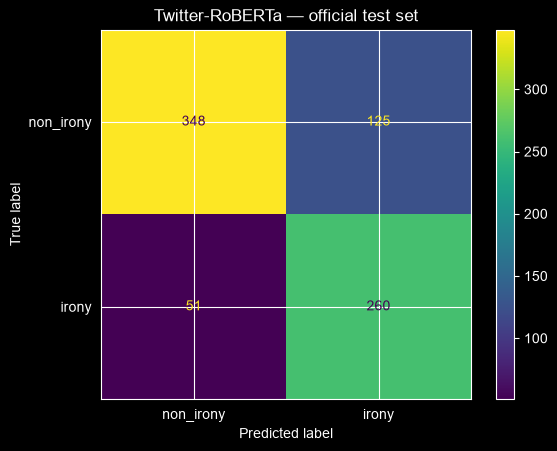

In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_output = final_trainer.predict(tw_tokenized_ds["test"])

y_true_test = test_output.label_ids                           # correct answers
y_pred_test = np.argmax(test_output.predictions, axis=-1)     # biggest of the 2 scores -> 0 or 1

print("Official test macro-F1:", round(f1_score(y_true_test, y_pred_test, average="macro"), 4))
print()
print(classification_report(y_true_test, y_pred_test, target_names=["non_irony", "irony"], digits=3))

ConfusionMatrixDisplay.from_predictions(y_true_test, y_pred_test, display_labels=["non_irony", "irony"])
plt.title("Twitter-RoBERTa — official test set")
plt.show()

#### 11.3 How much do the leftover hashtags help?

The dataset creators removed `#not`, `#irony` and `#sarcasm` from train and validation, but some are still present in the test set. These hashtags almost give away the answer, so the official test score may be inflated. We measure (a) how many test tweets contain them, (b) the accuracy on tweets with vs without them, and (c) the score on the whole test set after removing them.

`\b` in the pattern is a word boundary, so `#nothing` is not matched; `IGNORECASE` also catches `#NOT` or `#Sarcasm`.

In [29]:
import re

HASHTAG_RE = re.compile(r"#(?:not|irony|sarcasm)\b", flags=re.IGNORECASE)

# True/False per test tweet (same order as the predictions: the test set was never shuffled or filtered)
has_tag = test_df["text"].str.contains(HASHTAG_RE).to_numpy()

print(f"Test tweets with #not/#irony/#sarcasm: {has_tag.sum()} / {len(has_tag)}")
print("Share of ironic tweets among them:   ", round(y_true_test[has_tag].mean(), 3))
print("Share of ironic tweets among the rest:", round(y_true_test[~has_tag].mean(), 3))

Test tweets with #not/#irony/#sarcasm: 431 / 784
Share of ironic tweets among them:    0.722
Share of ironic tweets among the rest: 0.0


In [30]:
# The tweets WITHOUT a hashtag are all non-ironic (see the cell above), so macro-F1 makes no
# sense on that group (one class only). We compare accuracy per group instead.
acc_with = (y_pred_test[has_tag] == y_true_test[has_tag]).mean()
acc_without = (y_pred_test[~has_tag] == y_true_test[~has_tag]).mean()

print(f"Accuracy on tweets WITH a hashtag    (n = {has_tag.sum()}): {acc_with:.3f}")
print(f"Accuracy on tweets WITHOUT a hashtag (n = {(~has_tag).sum()}): {acc_without:.3f}")

Accuracy on tweets WITH a hashtag    (n = 431): 0.833
Accuracy on tweets WITHOUT a hashtag (n = 353): 0.705


Now we delete the hashtags from every test tweet and predict again. After deleting, the spaces are normalized again (same as section 3.2), otherwise the removal would leave double spaces — the exact leak we fixed. The labels do not change, only the text.

In [31]:
test_clean_df = test_df.copy()
test_clean_df["text"] = (
    test_clean_df["text"]
    .str.replace(HASHTAG_RE, "", regex=True)   # delete the hashtags
    .str.split()
    .str.join(" ")                             # back to single spaces
)

ds_test_clean = Dataset.from_pandas(test_clean_df)
ds_test_clean = ds_test_clean.map(lambda batch: {"text": [preprocess(t) for t in batch["text"]]}, batched=True)
tw_test_clean = ds_test_clean.map(tw_tokenize, batched=True)

clean_output = final_trainer.predict(tw_test_clean)
y_pred_clean = np.argmax(clean_output.predictions, axis=-1)

print("Test macro-F1 WITHOUT the hashtags:", round(f1_score(y_true_test, y_pred_clean, average="macro"), 4))
print(classification_report(y_true_test, y_pred_clean, target_names=["non_irony", "irony"], digits=3))

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

Map:   0%|          | 0/784 [00:00<?, ? examples/s]

Test macro-F1 WITHOUT the hashtags: 0.7412
              precision    recall  f1-score   support

   non_irony      0.826     0.734     0.777       473
       irony      0.654     0.765     0.705       311

    accuracy                          0.746       784
   macro avg      0.740     0.749     0.741       784
weighted avg      0.758     0.746     0.749       784



#### 11.4 Test results

| Test version | Score |
|---|---|
| Official test set — macro-F1 | **0.773** |
| — accuracy on tweets with a hashtag (n = 431) | 0.833 |
| — accuracy on tweets without a hashtag (n = 353, all non-ironic) | 0.705 |
| Test set with the hashtags removed — macro-F1 | **0.741** |
| *(reminder) validation, mean of 3 seeds* | *0.745* |

**Interpretation**
- **The test set is not built like train and validation.** Every ironic test tweet contains `#not`, `#irony` or `#sarcasm`, while all 353 tweets without one are non-ironic. In train and validation these hashtags were deleted, so the official test set contains a shortcut that the other splits do not.
- **The hashtags inflate the official score by about 0.03** (0.773 → 0.741). The model never saw these hashtags in our training data, but Twitter-RoBERTa was pre-trained on millions of tweets where `#not` and `#sarcasm` signal irony, so it still recognizes them.
- **The score without hashtags (0.741) matches the validation estimate (0.745 ± 0.003).** The model generalizes to new tweets as expected; we report **0.741** as our honest test score and 0.773 as the official one.
- **Main weakness: false irony.** About 30% of the non-ironic tweets without a hashtag are predicted ironic (accuracy 0.705 on that group), and irony recall (0.765–0.836) is higher than irony precision (0.65–0.68). The model tends to see irony where there is none. Section 12 looks at these errors in detail.

### 12. Error analysis

A score says *how often* the model is wrong, not *why*. Here we read the mistakes of the final model on the **test set without the hashtags** (the honest version from 11.3), and compare them with the best classical model, Logistic Regression.

For each tweet we also keep `p_irony`, the probability of irony given by the model. The logits (2 raw scores) are turned into probabilities with **softmax**, which makes them positive and sum to 1. A wrong answer with `p_irony` close to 0 or 1 is a **confident mistake**: those are the most interesting ones to read.

In [32]:
import torch

# Probability of the class "irony" for each test tweet (softmax over the 2 logits, keep column 1)
p_irony = torch.softmax(torch.tensor(clean_output.predictions), dim=-1)[:, 1].numpy()

analysis = pd.DataFrame({
    "text": test_clean_df["text"],
    "true": y_true_test,
    "pred": y_pred_clean,
    "p_irony": p_irony.round(3),
})

# TP = ironic & found, TN = not ironic & found, FP = false irony, FN = missed irony
analysis["result"] = np.select(
    [(analysis["true"] == 1) & (analysis["pred"] == 1),
     (analysis["true"] == 0) & (analysis["pred"] == 0),
     (analysis["true"] == 0) & (analysis["pred"] == 1)],
    ["TP", "TN", "FP"],
    default="FN",
)

print(analysis["result"].value_counts())

result
TN    347
TP    238
FP    126
FN     73
Name: count, dtype: int64


#### 12.1 False irony (FP): non-ironic tweets predicted ironic

The 10 tweets the model was **most sure** were ironic, while they are not.

In [33]:
pd.set_option("display.max_colwidth", None)   # show the full tweet text

analysis[analysis["result"] == "FP"].sort_values("p_irony", ascending=False).head(10)[["text", "p_irony"]]

,text,p_irony
5,Corny jokes are my absolute favorite,0.998
90,You are taking your responsibilities so seriously today that i... More for Leo,0.998
216,Once again @user is re writing history re: #CubaEmbargo ! *primal scream* #tcot,0.998
700,Today was a very good day in Iceland.,0.998
197,Nice touch. All the bar staff in the ground wearing #saintsfc t shirts,0.997
71,Getting Final Jeopardy correct on Kids Jeopardy boosts my self-esteem,0.997
524,@user Ahem... yeah.. something like that ;) is one of the few things keeping sanity when facing RU propaganda. #CrazyIvan,0.997
204,@user his daughter is painting his toes! That is a parenting WIN in my book.,0.997
373,I wonder how many people who visit food banks have huge TVs or are drunks? #freedomofspeech #foodbanks,0.996
10,Most important thing I've learned in school,0.996


#### 12.2 Missed irony (FN): ironic tweets predicted non-ironic

The 10 ironic tweets the model was **most sure** were not ironic.

In [34]:
analysis[analysis["result"] == "FN"].sort_values("p_irony").head(10)[["text", "p_irony"]]

,text,p_irony
4,So much at work mate 10/10 #boring 100% #dead mate full on #shit absolutely #sleeping mate can't handle the,0.004
274,"My dad's still gonna get me santa's gifts since it's my last year before 18, but I really don't know what to ask for...",0.004
613,"Few #relations are by #chance, few are by #choice and few are by #Facebook!!",0.004
91,@user @user @user @user @user we get it right for business the trickle down fairy will do the rest,0.005
498,08:01am on the dot and the buzzer rings #helloworld #sleepy #tired #nothanks,0.005
219,What to do with that old #motherboard you have laying around. #guitarpicks,0.006
267,I may or may not have put @user at the top of @user tree soon as he likes Christmas time...,0.006
682,How can u miss something u never had?||#randomthoughts #miss |http://t.co/G5jLy9IKqn,0.008
633,@user maybe you should grind the gym man #calling #you #fat,0.010
231,i just enjoy throwing up #hatethis #sick #wanna #go #to #school #for #once #take #me #away,0.010


#### 12.3 Comparison with the classical model

To compare the *mistakes* (not only the scores), we use the best classical model of notebook 02 (task B): Logistic Regression built with B's shared `build_pipeline()` (TF-IDF settings from `src/config.py`) and **the hyperparameters B chose by 5-fold cross-validation**, read from `results/metrics_B.csv`. It is trained on Task A's cleaned text (`text_clean`) and evaluated on the same test tweets with the hashtags removed, so both models face the same task.

*(Notebook 05 compares all the models officially; this is only a reference for the error analysis.)*

In [35]:
import ast
from sklearn.linear_model import LogisticRegression
from src.model import build_pipeline        # task B's shared pipeline: TF-IDF (src/config.py) + classifier

proc_train = pd.read_csv("../data/processed/train.csv", keep_default_na=False)
proc_test = pd.read_csv("../data/processed/test.csv", keep_default_na=False)   # same order as test_df

# Task B's hyperparameters, chosen by 5-fold CV in notebook 02 (e.g. "clf__C=3; clf__class_weight=None")
b_params = pd.read_csv("../results/metrics_B.csv").set_index("model").loc["LogisticRegression", "params"]
lr_params = {key.strip(): ast.literal_eval(value) for key, value in (p.split("=") for p in b_params.split(";"))}

logreg = build_pipeline(LogisticRegression(max_iter=1000, random_state=42))
logreg.set_params(**lr_params)
logreg.fit(proc_train["text_clean"], proc_train["label"])

# Same hashtag removal + space normalization as for the transformer
test_text_lr = proc_test["text_clean"].str.replace(HASHTAG_RE, "", regex=True).str.split().str.join(" ")
y_pred_lr = logreg.predict(test_text_lr)

print("LogReg          — test macro-F1 (hashtags removed):", round(f1_score(y_true_test, y_pred_lr, average="macro"), 4))
print("Twitter-RoBERTa — test macro-F1 (hashtags removed):", round(f1_score(y_true_test, y_pred_clean, average="macro"), 4))

analysis["logreg_pred"] = y_pred_lr
rob_ok = analysis["pred"] == analysis["true"]
lr_ok = analysis["logreg_pred"] == analysis["true"]

pd.crosstab(rob_ok.rename("Twitter-RoBERTa correct"), lr_ok.rename("LogReg correct"), margins=True)

LogReg          — test macro-F1 (hashtags removed): 0.6604
Twitter-RoBERTa — test macro-F1 (hashtags removed): 0.7412


LogReg correct,False,True,All
Twitter-RoBERTa correct,,,
False,118,81,199
True,145,440,585
All,263,521,784


How to read the table: the diagonal is where both models agree (both right, or both wrong). The two other cells show the tweets where **only one** of them is right — that is where the transformer's understanding of context makes (or does not make) a difference.

Tweets that **only Twitter-RoBERTa** gets right:

In [36]:
analysis[rob_ok & ~lr_ok].sample(8, random_state=42)[["text", "true", "p_irony"]]

,text,true,p_irony
392,That moment when the ad plays flawlessly but the video keeps buffering #YouTube @user,1,0.977
757,"you seem super smart MT ""@GrannyMarried: @user @user ||#NO #BLEEDING happening in #WaterBoarding = it's #Torture""",1,0.989
144,@user Minky Wale tail fritter for price of a bijoux flat in Port Talbot.,0,0.010
121,Testing water temperatures #excitingtimes,1,0.998
262,@user @user Probably my favourite book. Couldn't put it down. 5Stars!,0,0.006
612,@user Things also go slowly when you are waiting for them especially!,0,0.156
679,Please snow let us get out of dance early,0,0.067
563,#tbt Dedicated to those days we DONT want to throwback to. Like this evil cold November day at...,0,0.089


Tweets that **only LogReg** gets right:

In [37]:
analysis[~rob_ok & lr_ok].sample(8, random_state=42)[["text", "true", "p_irony"]]

,text,true,p_irony
303,clashupdate,1,0.244
25,@user hmm... let me think about that,1,0.014
223,Never seen the gym so packed,0,0.958
304,@user Super Junior's Henry asks sasaeng fans to let him sleep|http://t.co/BhrEKEtMka Henry oppa >^<,0,0.607
197,Nice touch. All the bar staff in the ground wearing #saintsfc t shirts,0,0.997
285,@user @user @user Just wait till Cleveland comes again!,1,0.237
109,HAHAHAHA!! Oops.......I'm addicted to @user Tweets sooo FUNNY! You Got to follow him for #HILARIOUS #tweets #RT.,0,0.898
699,I have three exams today lets gooooo! #School #Swag,1,0.072


#### 12.4 What the errors show

On the test set without hashtags, the model makes **126 false ironies (FP)** and **73 missed ironies (FN)**, against 347 TN and 238 TP: it errs mostly on the side of seeing irony.

**False irony — enthusiasm read as sarcasm.** The most confident FPs are short, very positive statements: *"Corny jokes are my absolute favorite"*, *"Today was a very good day in Iceland."*, *"Getting Final Jeopardy correct on Kids Jeopardy boosts my self-esteem"* (all at p ≥ 0.997). The model has learned that exaggerated positivity is a strong sign of irony — which is true in this dataset — but it cannot tell a sincere compliment from a sarcastic one without context. Several of these tweets could honestly be read as ironic by a human too: part of the "errors" are **ambiguous labels**, not only model mistakes.

**Missed irony — irony carried by hashtags or by the situation.** The most confident FNs (p ≤ 0.01) are of two kinds:
- tweets whose irony lives in **hashtags that contradict the text** (*"i just enjoy throwing up #hatethis #sick ..."*, *"08:01am on the dot and the buzzer rings #helloworld #sleepy #tired #nothanks"*), or **situational irony** that needs world knowledge (*"What to do with that old #motherboard ... #guitarpicks"*);
- tweets **damaged by our hashtag removal**: in *"So much #sarcasm at work mate..."* or *"#NOT GONNA WIN"*, the hashtag was a word of the sentence, so removing it leaves an incomplete text (*"So much at work mate..."*, *"GONNA WIN"*). The score without hashtags (0.741) is therefore a slightly **pessimistic** estimate, and the official score (0.773) an optimistic one: the true performance lies between the two.

**Twitter-RoBERTa vs LogReg (same 784 tweets):**

| | LogReg wrong | LogReg right |
|---|---|---|
| **Twitter-RoBERTa wrong** | 118 | 81 |
| **Twitter-RoBERTa right** | 145 | 440 |

- The transformer corrects **145** of LogReg's errors and introduces **81** new ones: a net gain of 64 tweets (+0.08 macro-F1).
- Where only Twitter-RoBERTa is right, the irony lies in the **contrast between two parts of the tweet** (*"the ad plays flawlessly but the video keeps buffering"*), or a positive tweet is correctly kept **sincere** (*"Probably my favourite book. Couldn't put it down. 5Stars!"*) where LogReg only sees the word *favourite*. This needs word order and context — exactly what a bag of words throws away.
- Where only LogReg is right, Twitter-RoBERTa again over-reads enthusiasm (*"Never seen the gym so packed"*, *"HAHAHAHA!! ... sooo FUNNY!"*).
- **118 tweets (15%) are missed by both models**: a hard core of tweets where irony depends on information that is not in the text.

### 13. Saving the results for the comparison notebook

Every model of the project writes its scores to `results/metrics_<task>.csv` with the **same columns** (`model, split, accuracy, precision, recall, f1, f1_macro, params`), so notebook 05 can put all models in one table. `precision`, `recall` and `f1` are for the class *irony*; `f1_macro` is the main metric.

We write three rows for the final model: validation, official test, and test with the hashtags removed.

In [38]:
from sklearn.metrics import precision_score, recall_score

PARAMS = "cardiffnlp/twitter-roberta-base; lr=2e-5; 4 epochs (best on val); batch 16; max_length 64; seed 42"

def metrics_row(split, y_true, y_pred):
    return {
        "model": "Twitter-RoBERTa",
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
        "params": PARAMS,
    }

# Validation predictions of the same saved model
val_output = final_trainer.predict(tw_tokenized_ds["validation"])
y_pred_val = np.argmax(val_output.predictions, axis=-1)

metrics_D = pd.DataFrame([
    metrics_row("validation", val_output.label_ids, y_pred_val),
    metrics_row("test", y_true_test, y_pred_test),
    metrics_row("test_no_hashtags", y_true_test, y_pred_clean),
])
metrics_D.to_csv("../results/metrics_D.csv", index=False)

metrics_D.drop(columns="params").round(4)

,model,split,accuracy,precision,recall,f1,f1_macro
0,Twitter-RoBERTa,validation,0.7403,0.7140,0.7610,0.7367,0.7403
1,Twitter-RoBERTa,test,0.7755,0.6753,0.8360,0.7471,0.7726
2,Twitter-RoBERTa,test_no_hashtags,0.7462,0.6538,0.7653,0.7052,0.7412


### 14. Conclusion

**Final model:** Twitter-RoBERTa (`cardiffnlp/twitter-roberta-base`), fine-tuned 4 epochs on the raw tweets (mentions → `@user`, links → `http`).

| | Macro-F1 |
|---|---|
| Validation (mean of 3 seeds) | 0.745 ± 0.003 |
| Test — official | 0.773 |
| **Test — hashtags `#not`/`#irony`/`#sarcasm` removed** | **0.741** |
| LogReg on the same test, for reference | 0.660 |

**What we learned**
1. **Check the data before trusting a score.** Our first Twitter-RoBERTa reached 0.92: the cause was not the model but a **leak** — the dataset creators deleted the irony hashtags but left the extra spaces, and RoBERTa's tokenizer sees spaces. Normalizing whitespace (section 3.2) brought scores back to realistic values. The test set has a similar trap: every ironic tweet still contains one of these hashtags, which inflates the official score by about 0.03.
2. **One run is not a result.** Repeating training with 3 seeds showed a run-to-run noise of ~0.004, much smaller than the gaps between models: the ranking DistilBERT (0.676) < roberta-base (0.720) < Twitter-RoBERTa (0.745) is real.
3. **Each step of the ranking has a reason.** Keeping capitals and emojis (RoBERTa's cased, byte-level tokenizer) adds about +0.04; pre-training on tweets adds about +0.025.
4. **Validation predicted the test well** (0.745 vs 0.741): choosing the model on validation and touching the test only once gave an honest estimate.
5. **Context is what the transformer adds**, compared with TF-IDF models: it handles contrasts inside a tweet and sincere positive tweets better, but still over-reads enthusiasm as sarcasm and misses irony that needs outside knowledge.

**Limits and next steps**
- Small dataset (2,859 training tweets) and some ambiguous labels: part of the remaining errors cannot be fixed by the model alone.
- The model overfits quickly (validation loss rises after epoch 2); more data or stronger regularization would help more than more epochs.
- Possible improvements: averaging the 3 seed models (ensemble), or adding the tweet's context (the conversation it replies to).

---

# Part 5 — Final comparison, choice of the model & conclusion

*(source: `notebooks/05_comparison.ipynb`)*

## 05 — Final comparison of all models

**Project:** Irony detection in tweets — TweetEval `irony` (SemEval-2018 Task 3)
**This notebook:** evaluate every model of the project on the **test set**, put them in one comparison table and justify the choice of the final model.
**Tools:** pandas · scikit-learn · matplotlib

**Where the models come from**
- Naive Bayes, Logistic Regression → notebook 02 (task B)
- SVM, Random Forest, KNN → notebook 03 (task C)
- Twitter-RoBERTa (transformer) → notebook 04 (task D)

The classical models are **rebuilt from the settings each task chose by cross-validation** (the `params` column of `results/metrics_B.csv` and `metrics_C.csv`) with the shared `build_pipeline()`, then trained once on the training set. The transformer's test scores are read from `results/metrics_D.csv` (it needs a GPU and was evaluated in notebook 04).

### 1. Imports

In [1]:
import sys
sys.path.append("..")

import ast
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

from src.config import PROCESSED_DIR, RESULTS, RANDOM_STATE, TEXT_COL, LABEL_NAMES
from src.model import build_pipeline

### 2. Data

Same cleaned files as every other notebook (Task A's `text_clean`). The test set is used here for the first and only time for the classical models.

**Two versions of the test set.** Notebook 04 showed that every ironic test tweet still contains `#not`, `#irony` or `#sarcasm` (these hashtags were deleted from train and validation, not from test). So we evaluate every model on the **official test** and on the **test with these hashtags removed** — the second one is the fair comparison, because no model saw these hashtags during training.

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv", keep_default_na=False)
test = pd.read_csv(PROCESSED_DIR / "test.csv", keep_default_na=False)

X_train, y_train = train[TEXT_COL], train["label"]
y_test = test["label"].to_numpy()

HASHTAG_RE = re.compile(r"#(?:not|irony|sarcasm)\b", flags=re.IGNORECASE)

TEST_SETS = {
    "test": test[TEXT_COL],
    "test_no_hashtags": test[TEXT_COL].str.replace(HASHTAG_RE, "", regex=True).str.split().str.join(" "),
}

print("train:", X_train.shape, "| test:", y_test.shape)
print("test tweets containing #not/#irony/#sarcasm:", test[TEXT_COL].str.contains(HASHTAG_RE).sum())

train: (2859,) | test: (784,)
test tweets containing #not/#irony/#sarcasm: 431


### 3. The settings chosen by each task

Each task saved its tuned models to `results/metrics_<task>.csv`, with the validation scores and the hyperparameters chosen by 5-fold cross-validation on train.

In [3]:
SPLITS = {"validation", "test", "test_no_hashtags"}

def read_metrics(task):
    df = pd.read_csv(RESULTS / f"metrics_{task}.csv")
    return df[df["split"].isin(SPLITS)]          # ignore any malformed row

metrics = pd.concat([read_metrics(t) for t in ["B", "C", "D"]], ignore_index=True)
metrics[metrics["split"] == "validation"][["model", "f1_macro", "params"]].round(4)

,model,f1_macro,params
0,MultinomialNB,0.6314,clf=MultinomialNB(); clf__alpha=2.0
1,LogisticRegression,0.6469,clf__C=3; clf__class_weight=None
2,SVM tuned,0.6197,clf__C=0.5
3,Random Forest tuned,0.6126,clf__max_depth=None; clf__min_samples_leaf=1; ...
4,KNN tuned,0.6414,clf__metric=cosine; clf__n_neighbors=21; clf__...
5,Twitter-RoBERTa,0.7403,cardiffnlp/twitter-roberta-base; lr=2e-5; 4 ep...


### 4. Rebuilding the classical models

`params` is a text like `clf__C=3; clf__class_weight=None`. We turn it back into a dictionary (`{"clf__C": 3, "clf__class_weight": None}`) and give it to the shared pipeline with `set_params`, so each model is exactly the one its task selected.

In [4]:
ESTIMATORS = {"MultinomialNB": MultinomialNB, "ComplementNB": ComplementNB}

def parse_value(text):
    text = text.strip()
    if text.endswith("()") and text[:-2] in ESTIMATORS:      # e.g. "MultinomialNB()"
        return ESTIMATORS[text[:-2]]()
    try:
        return ast.literal_eval(text)                          # numbers, None, True, tuples...
    except (ValueError, SyntaxError):
        return text                                            # plain words: "cosine", "distance"

def parse_params(params):
    if not isinstance(params, str) or not params.strip():
        return {}
    pairs = [p.split("=", 1) for p in params.split(";")]
    return {key.strip(): parse_value(value) for key, value in pairs}

def base_classifier(model_name):
    name = model_name.lower()
    if "nb" in name or "bayes" in name:
        return MultinomialNB()
    if "logistic" in name:
        return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    if "svm" in name or "svc" in name:
        return LinearSVC(max_iter=10000, random_state=RANDOM_STATE)
    if "forest" in name or name.startswith("rf"):
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    if "knn" in name or "neighbor" in name:
        return KNeighborsClassifier()
    raise ValueError(f"Unknown model: {model_name}")

classical = metrics[(metrics["split"] == "validation") & (metrics["model"] != "Twitter-RoBERTa")]

models = {}
for _, row in classical.iterrows():
    pipe = build_pipeline(base_classifier(row["model"]))
    pipe.set_params(**parse_params(row["params"]))
    pipe.fit(X_train, y_train)
    models[row["model"]] = pipe
    print(f"{row['model']:<22} {parse_params(row['params'])}")

MultinomialNB          {'clf': MultinomialNB(), 'clf__alpha': 2.0}
LogisticRegression     {'clf__C': 3, 'clf__class_weight': None}


SVM tuned              {'clf__C': 0.5}


Random Forest tuned    {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
KNN tuned              {'clf__metric': 'cosine', 'clf__n_neighbors': 21, 'clf__weights': 'distance'}


### 5. Test evaluation of the classical models

In [5]:
def scores(model, split, y_true, y_pred):
    return {
        "model": model,
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }

test_rows, test_preds = [], {}
for name, pipe in models.items():
    for split, X in TEST_SETS.items():
        y_pred = pipe.predict(X)
        test_preds[(name, split)] = y_pred
        test_rows.append(scores(name, split, y_test, y_pred))

classical_test = pd.DataFrame(test_rows)
classical_test.round(4)

,model,split,accuracy,precision,recall,f1,f1_macro
0,MultinomialNB,test,0.6556,0.5547,0.6688,0.6064,0.6501
1,MultinomialNB,test_no_hashtags,0.6633,0.5575,0.7331,0.6333,0.6610
2,LogisticRegression,test,0.6441,0.5465,0.6045,0.5740,0.6342
3,LogisticRegression,test_no_hashtags,0.6645,0.5622,0.6977,0.6227,0.6604
4,SVM tuned,test,0.6531,0.5562,0.6206,0.5866,0.6439
5,SVM tuned,test_no_hashtags,0.6709,0.5692,0.7010,0.6282,0.6665
6,Random Forest tuned,test,0.6186,0.5180,0.5563,0.5364,0.6062
7,Random Forest tuned,test_no_hashtags,0.6365,0.5333,0.6688,0.5934,0.6324
8,KNN tuned,test,0.6135,0.5124,0.5305,0.5213,0.5986
9,KNN tuned,test_no_hashtags,0.6378,0.5368,0.6334,0.5811,0.6310


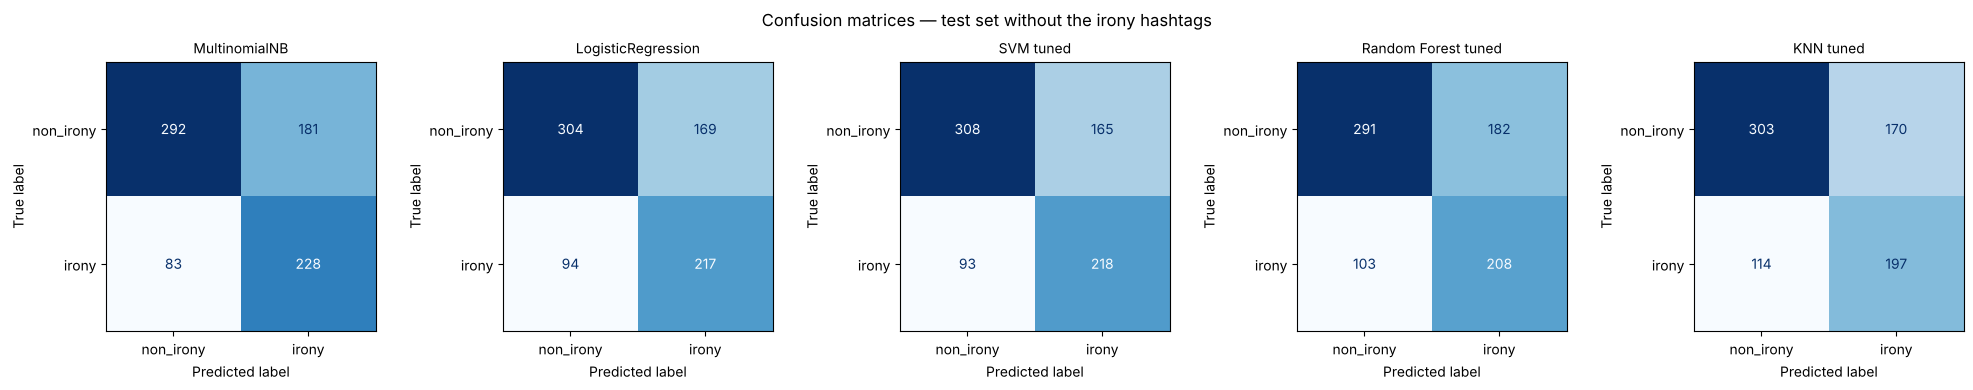

In [6]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.8))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, test_preds[(name, "test_no_hashtags")],
                                            display_labels=LABEL_NAMES, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.suptitle("Confusion matrices — test set without the irony hashtags")
plt.tight_layout()
plt.show()

### 6. Comparison table of all models

The transformer's rows come from `metrics_D.csv` (evaluated once in notebook 04, on the same two versions of the test set).

In [7]:
all_rows = pd.concat([
    metrics[metrics["split"].isin(["validation"])][["model", "split", "f1_macro"]],
    classical_test[["model", "split", "f1_macro"]],
    metrics[(metrics["model"] == "Twitter-RoBERTa") & metrics["split"].isin(["test", "test_no_hashtags"])][["model", "split", "f1_macro"]],
], ignore_index=True)

comparison = (all_rows.pivot_table(index="model", columns="split", values="f1_macro")
              [["validation", "test", "test_no_hashtags"]]
              .sort_values("test_no_hashtags", ascending=False)
              .round(3))
comparison

split,validation,test,test_no_hashtags
model,,,
Twitter-RoBERTa,0.740,0.773,0.741
SVM tuned,0.620,0.644,0.667
MultinomialNB,0.631,0.650,0.661
LogisticRegression,0.647,0.634,0.660
Random Forest tuned,0.613,0.606,0.632
KNN tuned,0.641,0.599,0.631


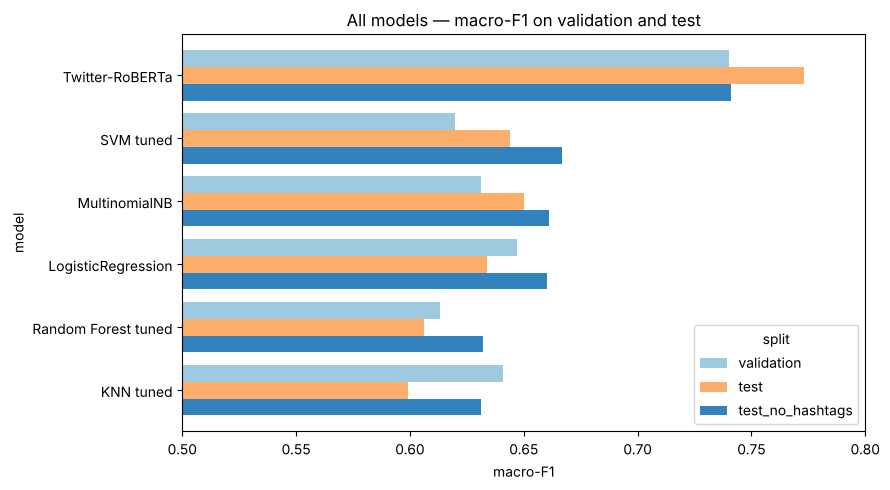

In [8]:
ax = comparison.plot(kind="barh", figsize=(9, 5), width=0.8, color=["#9ecae1", "#fdae6b", "#3182bd"])
ax.invert_yaxis()
ax.set_xlim(0.5, 0.8)
ax.set_xlabel("macro-F1")
ax.set_title("All models — macro-F1 on validation and test")
ax.legend(title="split", loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
full_test = pd.concat([
    classical_test,
    metrics[(metrics["model"] == "Twitter-RoBERTa") & (metrics["split"] == "test_no_hashtags")],
], ignore_index=True)

(full_test[full_test["split"] == "test_no_hashtags"]
 .drop(columns=["split", "params"], errors="ignore")
 .sort_values("f1_macro", ascending=False)
 .set_index("model")
 .round(3))

,accuracy,precision,recall,f1,f1_macro
model,,,,,
Twitter-RoBERTa,0.746,0.654,0.765,0.705,0.741
SVM tuned,0.671,0.569,0.701,0.628,0.667
MultinomialNB,0.663,0.557,0.733,0.633,0.661
LogisticRegression,0.665,0.562,0.698,0.623,0.660
Random Forest tuned,0.636,0.533,0.669,0.593,0.632
KNN tuned,0.638,0.537,0.633,0.581,0.631


In [10]:
final_table = pd.concat([metrics, classical_test], ignore_index=True)
final_table.to_csv(RESULTS / "comparison_all_models.csv", index=False)
print("Saved: results/comparison_all_models.csv")

Saved: results/comparison_all_models.csv


### 7. Choice of the final model

**Final model: Twitter-RoBERTa** (notebook 04).

| | Best classical model (SVM) | Twitter-RoBERTa | Gain |
|---|---|---|---|
| Test macro-F1, hashtags removed (fair comparison) | 0.667 | **0.741** | **+0.074** |
| Test macro-F1, official | 0.650 (Naive Bayes) | **0.773** | +0.123 |
| Irony recall (hashtags removed) | 0.70 | **0.77** | |
| Irony precision (hashtags removed) | 0.57 | **0.65** | |

**Why this choice**
1. **It is the best model on every metric and every version of the test set**, by a large margin.
2. **The margin is far above the noise.** The five classical models are within 0.04 of each other and their order changes between validation and test (KNN is 2nd on validation, last on test; SVM is 4th on validation, 1st on test): their differences are mostly noise. The transformer's lead (+0.07) is much larger than those fluctuations, and notebook 04 showed that its own run-to-run noise is only ±0.003 (3 seeds).
3. **It is the only model that reads context.** TF-IDF models count words; irony lives in the contrast between words (*"I love waiting 2 hours at the doctor"*). The error analysis of notebook 04 shows the transformer wins precisely on those contrasts.
4. **Its validation estimate was honest:** 0.745 on validation (3 seeds) vs 0.741 on the fair test.

**Cost of this choice:** training needs a GPU (~2 min per run on an RTX 5060 Ti) and the model weighs ~500 MB, against a few seconds and a few MB for Logistic Regression. If a fast, light, explainable model were required, **Logistic Regression** would be the classical choice: almost as good as the best classical model, and its weights show which words signal irony (notebook 02).

### 8. Conclusion

**What the comparison shows**
- **Classical models plateau around 0.63–0.67 macro-F1.** Whatever the algorithm (probabilistic, linear, trees, neighbors), a bag of words only sees which words appear. On irony, that is not enough: the same word ("love", "great") is sincere in one tweet and ironic in the next.
- **Linear models do best among classical ones** (SVM, Naive Bayes, Logistic Regression), while Random Forest and KNN struggle with thousands of sparse TF-IDF features.
- **The leftover hashtags behave differently for the two families.** The classical models score *lower* on the official test than without the hashtags: they never saw `#not` in training, so it is just noise for them. Twitter-RoBERTa scores *higher* with them, because its pre-training on millions of tweets taught it that `#not` and `#sarcasm` mean irony. The fair comparison is therefore the test without these hashtags.
- **Context is what makes the difference:** fine-tuning a transformer pre-trained on tweets gives +0.07 macro-F1 over the best classical model.

**Limits:** a small dataset (2,859 training tweets), some ambiguous labels, and irony that often depends on information that is not in the tweet itself.